# [16.9] Influence Functions and TracIn

## Introduction

Which training images helped a prediction, and what changes if we remove them?

This lesson follows one question through three different experiments: slightly
change an example's weight, follow the loss along training, and actually retrain
without that example. You will derive and implement each calculation before
comparing them on real handwritten digits.

## Learning Objectives

By the end, you should be able to:

- compute influence with a Hessian-vector product and a checked linear solve;
- explain what regularization changes in a leave-one-out approximation;
- distinguish exact single-example path accounting, its Taylor approximation and TracInCP;
- identify helpful and harmful images for a particular query, then test a deletion policy;
- recognize when an approximation's sign or ranking fails.

You should be comfortable with gradients, matrix multiplication and the training
loop from original ARENA [0.3 Optimization](../../../chapter0_fundamentals/exercises/part3_optimization/0.3_Optimization_exercises.ipynb).
Section [16.7](../part7_data_shapley_in_one_training_run/README.md) supplies the nearby data-value
question. An influence score is not a Shapley value: keep the perturbation and
training procedure in view.

The complete reference experiment runs on CPU. Allow several hours to implement
the exercises and investigate the results; the reference fits themselves are
small enough to rerun while exploring.


In [1]:
from pathlib import Path
from collections.abc import Callable
import math
import os
import sys

import numpy as np
import torch
from torch import Tensor
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "chapter16_shapley_attribution_baselines").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from chapter16_shapley_attribution_baselines.exercises.part9_influence_and_tracin import (
    attribution_methods_tests as tests,
)
from chapter16_shapley_attribution_baselines.exercises.part9_influence_and_tracin.attribution_data import (
    load_study_data,
    data_manifest,
)

DTYPE = torch.float64
torch.set_num_threads(4)
OUTPUT = Path(
    os.environ.get("ARENA_ATTRIBUTION_OUTPUT_DIRECTORY", "/tmp/arena16_9_influence_tracin")
)
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)


def show_figure(figure, name, **layout):
    figure.tight_layout(**layout)
    figure.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


## A familiar image can carry the wrong training label

Data: [Alpaydin and Kaynak (1998), Optical Recognition of Handwritten Digits](https://doi.org/10.24432/C50P49),
provided by UCI under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
We display the supplied 8×8 pixel counts divided by sixteen; the deliberate label
changes are identified below.

These are actual UCI handwritten images. We deliberately flip twelve training
labels in one experimental condition and retain a clean-label condition as a
control. The true source labels remain available. An attribution method only
receives the labels used for training; it does not receive the corruption mask.

Before running the cell, predict whether a mislabeled image must hurt every
query. Consider a query from each class. “Helpful” will always be relative to a
particular loss, label and model, rather than an intrinsic property of an image.


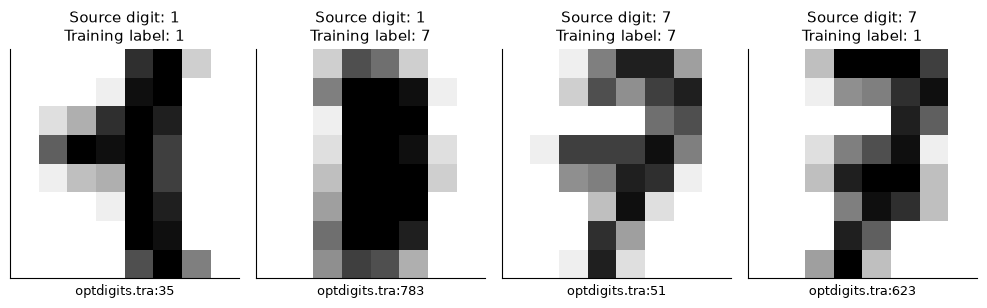

In [2]:
data = load_study_data()
import json

manifest_path = (
    ROOT
    / "chapter16_shapley_attribution_baselines/exercises/part9_influence_and_tracin/data_manifest.json"
)
assert data_manifest(data) == json.loads(manifest_path.read_text())
train = data["train"]
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, (digit, flipped) in zip(axes, [(1, False), (1, True), (7, False), (7, True)]):
    index = (
        torch.nonzero((train["digit"] == digit) & (train["flipped"] == flipped)).flatten()[0].item()
    )
    ax.imshow(train["images"][index], cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    observed = 7 if train["corrupted_y"][index] else 1
    ax.set_title(f"Source digit: {digit}\nTraining label: {observed}", fontsize=11)
    ax.set_xlabel(train["ids"][index], fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
show_figure(fig, "attribution_training_images")


## 1️⃣ Start with a loss you can differentiate

Let $x_i\in\mathbb{R}^p$ include a final constant coordinate for the bias, and
let $y_i\in\{0,1\}$. Our logistic model predicts $p_i=\sigma(x_i^T\theta)$.
The per-example negative log-likelihood is

$$\ell_i(\theta)=\operatorname{softplus}(x_i^T\theta)-y_i x_i^T\theta.$$

We use $R(\theta)=\lambda\|\theta\|^2/2$, including the bias. Write
$q_i=\ell_i+R$. This convention will matter when an example is removed.
Queries use $\ell$, without the regularizer: we want their prediction loss.

Take the derivative on paper. Each example contributes one vector, not one
scalar and not an already averaged batch gradient.


### Exercise 1 — Keep the per-example gradients

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 15–20 minutes on this exercise.
```

Implement losses shaped `[examples]` and gradients shaped `[examples, parameters]`. With `l2=0`,
return data losses/gradients. With positive `l2`, include $R$ in every example. Do not take a mean
inside either function.

<details><summary>Help</summary>

The derivative of softplus is sigmoid. Each row has gradient
$(\sigma(x_i^T\theta)-y_i)x_i+\lambda\theta$. A common bug is adding the regularizer after averaging
incorrectly; the mean of your gradient rows must equal the gradient of the mean of your loss rows.

</details>

<details><summary>Expected output</summary>

Both checks print a success message. The loss check includes logits of magnitude 1000; confident correct predictions must stay finite and near zero.

</details>

<details><summary>Solution</summary>

```python
def logistic_losses(theta: Tensor, x: Tensor, y: Tensor, l2: float = 0.0) -> Tensor:
    """Unreduced per-example losses, optionally including R(theta) in each row."""
    if theta.ndim != 1 or x.ndim != 2 or x.shape[1] != theta.numel() or y.shape != (len(x),):
        raise ValueError("Expected theta [parameters], x [examples, parameters], y [examples].")
    if not ((y == 0) | (y == 1)).all() or not math.isfinite(l2) or l2 < 0:
        raise ValueError("Use binary labels and a finite nonnegative regularizer.")
    logits = x @ theta
    return F.softplus(logits) - y * logits + 0.5 * l2 * theta.square().sum()


def logistic_gradients(theta: Tensor, x: Tensor, y: Tensor, l2: float = 0.0) -> Tensor:
    """Per-example parameter gradients; their mean is the objective gradient."""
    logistic_losses(theta, x, y, l2)  # Validate the common public contract.
    residual = torch.sigmoid(x @ theta) - y
    return residual[:, None] * x + l2 * theta[None, :]
```

</details>


In [3]:
def logistic_losses(theta: Tensor, x: Tensor, y: Tensor, l2: float = 0.0) -> Tensor:
    """Unreduced per-example losses, optionally including R(theta) in each row."""
    if theta.ndim != 1 or x.ndim != 2 or x.shape[1] != theta.numel() or y.shape != (len(x),):
        raise ValueError("Expected theta [parameters], x [examples, parameters], y [examples].")
    if not ((y == 0) | (y == 1)).all() or not math.isfinite(l2) or l2 < 0:
        raise ValueError("Use binary labels and a finite nonnegative regularizer.")
    logits = x @ theta
    return F.softplus(logits) - y * logits + 0.5 * l2 * theta.square().sum()



def logistic_gradients(theta: Tensor, x: Tensor, y: Tensor, l2: float = 0.0) -> Tensor:
    """Per-example parameter gradients; their mean is the objective gradient."""
    logistic_losses(theta, x, y, l2)  # Validate the common public contract.
    residual = torch.sigmoid(x @ theta) - y
    return residual[:, None] * x + l2 * theta[None, :]



tests.test_logistic_losses(logistic_losses)
tests.test_logistic_gradients(logistic_gradients)


All tests in test_logistic_losses passed!
All tests in test_logistic_gradients passed!


## 2️⃣ Make the counterfactual objective explicit

For nonnegative weights $a_i$ with positive total mass, define

$$F_a(\theta)=\frac{\sum_i a_i\ell_i(\theta)}{\sum_i a_i}+R(\theta).$$

Setting one weight to zero removes that image while preserving the specified
regularization strength. Multiplying all weights by nine leaves the objective
unchanged. By contrast, dividing by the original $n$ after removal and retaining
the same $R$ changes the relative penalty.

We will refit many counterfactuals. Give every fit its own row of weights and
parameters. Sharing matrix operations is useful; sharing its objective denominator
with another fit would change the experiment.


### Exercise 2 — Compute the weighted objective and its curvature

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 20–25 minutes on this exercise.
```

Use `theta [fits, parameters]`, `weights [fits, examples]` and one shared input matrix. Return one
objective per fit, then gradients `[fits, parameters]` and Hessians `[fits, parameters,
parameters]`. Reject negative weights and zero-mass fits.

<details><summary>Help</summary>

Normalize each row of weights separately. The scalar curvature of logistic loss is $p_i(1-p_i)$, so
each input contributes a scaled outer product $x_ix_i^T$. Add $\lambda I$ to every Hessian. Common
mistake: forgetting that the bias is regularized in this lesson.

</details>

<details><summary>Expected output</summary>

The checks compare every fit against independent autograd derivatives. Rescaling all weights changes
neither the objective nor its relative regularization.

</details>

<details><summary>Solution</summary>

```python
def weighted_objective(theta: Tensor, x: Tensor, y: Tensor, weights: Tensor, l2: float) -> Tensor:
    """One independent normalized objective per row of theta [fits, parameters]."""
    if theta.ndim != 2 or x.ndim != 2 or theta.shape[1] != x.shape[1]:
        raise ValueError("Expected theta [fits, parameters] and x [examples, parameters].")
    if weights.shape != (len(theta), len(x)) or y.shape != (len(x),):
        raise ValueError("Expected weights [fits, examples] and y [examples].")
    if not torch.isfinite(weights).all() or (weights < 0).any() or (weights.sum(1) <= 0).any():
        raise ValueError("Every fit needs finite nonnegative weights with positive total mass.")
    if not ((y == 0) | (y == 1)).all() or not math.isfinite(l2) or l2 < 0:
        raise ValueError("Use binary targets and a finite nonnegative regularizer.")
    probabilities = weights / weights.sum(1, keepdim=True)
    logits = theta @ x.T
    return ((F.softplus(logits) - y[None, :] * logits) * probabilities).sum(
        1
    ) + 0.5 * l2 * theta.square().sum(1)


def objective_derivatives(
    theta: Tensor, x: Tensor, y: Tensor, weights: Tensor, l2: float
) -> tuple[Tensor, Tensor]:
    """Gradient and dense Hessian of each independently weighted objective."""
    weighted_objective(theta, x, y, weights, l2)
    mass = weights / weights.sum(1, keepdim=True)
    probabilities = torch.sigmoid(theta @ x.T)
    gradient = ((probabilities - y[None, :]) * mass) @ x + l2 * theta
    curvature = probabilities * (1 - probabilities) * mass
    hessian = torch.einsum("np,bn,nq->bpq", x, curvature, x)
    hessian = hessian + l2 * torch.eye(x.shape[1], dtype=x.dtype, device=x.device)
    return gradient, hessian
```

</details>


In [4]:
def weighted_objective(theta: Tensor, x: Tensor, y: Tensor, weights: Tensor, l2: float) -> Tensor:
    """One independent normalized objective per row of theta [fits, parameters]."""
    if theta.ndim != 2 or x.ndim != 2 or theta.shape[1] != x.shape[1]:
        raise ValueError("Expected theta [fits, parameters] and x [examples, parameters].")
    if weights.shape != (len(theta), len(x)) or y.shape != (len(x),):
        raise ValueError("Expected weights [fits, examples] and y [examples].")
    if not torch.isfinite(weights).all() or (weights < 0).any() or (weights.sum(1) <= 0).any():
        raise ValueError("Every fit needs finite nonnegative weights with positive total mass.")
    if not ((y == 0) | (y == 1)).all() or not math.isfinite(l2) or l2 < 0:
        raise ValueError("Use binary targets and a finite nonnegative regularizer.")
    probabilities = weights / weights.sum(1, keepdim=True)
    logits = theta @ x.T
    return ((F.softplus(logits) - y[None, :] * logits) * probabilities).sum(
        1
    ) + 0.5 * l2 * theta.square().sum(1)



def objective_derivatives(
    theta: Tensor, x: Tensor, y: Tensor, weights: Tensor, l2: float
) -> tuple[Tensor, Tensor]:
    """Gradient and dense Hessian of each independently weighted objective."""
    weighted_objective(theta, x, y, weights, l2)
    mass = weights / weights.sum(1, keepdim=True)
    probabilities = torch.sigmoid(theta @ x.T)
    gradient = ((probabilities - y[None, :]) * mass) @ x + l2 * theta
    curvature = probabilities * (1 - probabilities) * mass
    hessian = torch.einsum("np,bn,nq->bpq", x, curvature, x)
    hessian = hessian + l2 * torch.eye(x.shape[1], dtype=x.dtype, device=x.device)
    return gradient, hessian



tests.test_weighted_objective(weighted_objective)
tests.test_objective_derivatives(objective_derivatives)


All tests in test_weighted_objective passed!
All tests in test_objective_derivatives passed!


## 3️⃣ Curvature changes which directions are expensive

A positive-definite Hessian describes the local resistance to moving the model.
The same gradient can produce a large parameter response along a weak-curvature
direction and a small response along a strong one. A plain gradient dot product
ignores this distinction.

For large models, storing every entry of $H$ is impractical. To compute $Hv$,
first project $v$ onto each input, weight by curvature, then map back to parameter
space. The following operation never needs a `[parameters, parameters]` array.


### Exercise 3 — Multiply by the Hessian without forming it

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 10–15 minutes on this exercise.
```

Implement one Hessian-vector product for a single fitted parameter vector. Keep the same normalized weights and regularizer as Exercise 2.

<details><summary>Help</summary>

Compute $X^T[c\odot(Xv)]+\lambda v$, where $c_i=(a_i/\sum_j a_j)p_i(1-p_i)$. A common mistake is
using the labels as curvature weights; labels affect the gradient but the logistic Hessian at fixed
parameters depends on $p_i$.

</details>

<details><summary>Expected output</summary>

The result matches an independent derivative of a directional gradient. It has shape `[parameters]`.

</details>

<details><summary>Solution</summary>

```python
def logistic_hvp(
    theta: Tensor, x: Tensor, y: Tensor, weights: Tensor, vector: Tensor, l2: float
) -> Tensor:
    """An objective Hessian-vector product without materializing a Hessian."""
    if theta.ndim != 1 or vector.shape != theta.shape or weights.shape != (len(x),):
        raise ValueError(
            "Use one parameter vector, one matching direction and one example-weight vector."
        )
    weighted_objective(theta[None], x, y, weights[None], l2)
    probabilities = torch.sigmoid(x @ theta)
    curvature = weights / weights.sum() * probabilities * (1 - probabilities)
    return x.T @ (curvature * (x @ vector)) + l2 * vector
```

</details>


In [5]:
def logistic_hvp(
    theta: Tensor, x: Tensor, y: Tensor, weights: Tensor, vector: Tensor, l2: float
) -> Tensor:
    """An objective Hessian-vector product without materializing a Hessian."""
    if theta.ndim != 1 or vector.shape != theta.shape or weights.shape != (len(x),):
        raise ValueError(
            "Use one parameter vector, one matching direction and one example-weight vector."
        )
    weighted_objective(theta[None], x, y, weights[None], l2)
    probabilities = torch.sigmoid(x @ theta)
    curvature = weights / weights.sum() * probabilities * (1 - probabilities)
    return x.T @ (curvature * (x @ vector)) + l2 * vector



tests.test_logistic_hvp(logistic_hvp)


All tests in test_logistic_hvp passed!


### Exercise 4 — Solve a curvature system and check the residual

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 20–25 minutes on this exercise.
```

Implement conjugate gradients using only a `matvec` function. Return the solution and a
residual-norm history. Stop only when the actual residual meets `atol + rtol * norm(rhs)`. Reject
nonpositive curvature and raise when the iteration budget is exhausted.

<details><summary>Help</summary>

Initialize $x=0$, $r=b-Ax$, $p=r$. Each step uses $\alpha=(r^Tr)/(p^TAp)$, then updates $x,r$ and
$p$. Check a zero right-hand side before dividing by its norm. Recurrence residuals can drift, so
verify $\|b-Ax\|$ before declaring success.

</details>

<details><summary>Expected output</summary>

A small positive-definite system matches a dense solve. A negative-definite system and an insufficient iteration budget fail explicitly.

</details>

<details><summary>Solution</summary>

```python
def conjugate_gradient(
    matvec: Callable[[Tensor], Tensor],
    rhs: Tensor,
    rtol: float = 1e-10,
    atol: float = 1e-12,
    max_steps: int | None = None,
) -> tuple[Tensor, Tensor]:
    """Solve an SPD system, returning the actual residual norms at every step."""
    if rhs.ndim != 1 or not torch.isfinite(rhs).all():
        raise ValueError("The right-hand side must be one finite vector.")
    if not all(math.isfinite(t) and t >= 0 for t in (rtol, atol)):
        raise ValueError("Residual tolerances must be finite and nonnegative.")
    max_steps = 2 * rhs.numel() if max_steps is None else max_steps
    if max_steps < 1:
        raise ValueError("Allow at least one CG step.")
    answer = torch.zeros_like(rhs)
    residual = rhs - matvec(answer)
    direction = residual.clone()
    squared_norm = residual @ residual
    threshold = atol + rtol * torch.linalg.vector_norm(rhs)
    history = [torch.linalg.vector_norm(residual)]
    if history[-1] <= threshold:
        return answer, torch.stack(history)
    for _ in range(max_steps):
        product = matvec(direction)
        curvature = direction @ product
        if not torch.isfinite(curvature) or curvature <= 0:
            raise ValueError("CG encountered nonpositive curvature; its SPD assumption failed.")
        alpha = squared_norm / curvature
        answer = answer + alpha * direction
        residual = residual - alpha * product
        # A recurrence residual can drift: success is checked against A @ answer.
        actual_norm = torch.linalg.vector_norm(rhs - matvec(answer))
        history.append(actual_norm)
        if actual_norm <= threshold:
            return answer, torch.stack(history)
        next_squared_norm = residual @ residual
        direction = residual + (next_squared_norm / squared_norm) * direction
        squared_norm = next_squared_norm
    raise RuntimeError(
        f"CG did not converge: residual {float(history[-1]):.3g} exceeds {float(threshold):.3g}."
    )
```

</details>


In [6]:
def conjugate_gradient(
    matvec: Callable[[Tensor], Tensor],
    rhs: Tensor,
    rtol: float = 1e-10,
    atol: float = 1e-12,
    max_steps: int | None = None,
) -> tuple[Tensor, Tensor]:
    """Solve an SPD system, returning the actual residual norms at every step."""
    if rhs.ndim != 1 or not torch.isfinite(rhs).all():
        raise ValueError("The right-hand side must be one finite vector.")
    if not all(math.isfinite(t) and t >= 0 for t in (rtol, atol)):
        raise ValueError("Residual tolerances must be finite and nonnegative.")
    max_steps = 2 * rhs.numel() if max_steps is None else max_steps
    if max_steps < 1:
        raise ValueError("Allow at least one CG step.")
    answer = torch.zeros_like(rhs)
    residual = rhs - matvec(answer)
    direction = residual.clone()
    squared_norm = residual @ residual
    threshold = atol + rtol * torch.linalg.vector_norm(rhs)
    history = [torch.linalg.vector_norm(residual)]
    if history[-1] <= threshold:
        return answer, torch.stack(history)
    for _ in range(max_steps):
        product = matvec(direction)
        curvature = direction @ product
        if not torch.isfinite(curvature) or curvature <= 0:
            raise ValueError("CG encountered nonpositive curvature; its SPD assumption failed.")
        alpha = squared_norm / curvature
        answer = answer + alpha * direction
        residual = residual - alpha * product
        # A recurrence residual can drift: success is checked against A @ answer.
        actual_norm = torch.linalg.vector_norm(rhs - matvec(answer))
        history.append(actual_norm)
        if actual_norm <= threshold:
            return answer, torch.stack(history)
        next_squared_norm = residual @ residual
        direction = residual + (next_squared_norm / squared_norm) * direction
        squared_norm = next_squared_norm
    raise RuntimeError(
        f"CG did not converge: residual {float(history[-1]):.3g} exceeds {float(threshold):.3g}."
    )



tests.test_conjugate_gradient(conjugate_gradient)


All tests in test_conjugate_gradient passed!


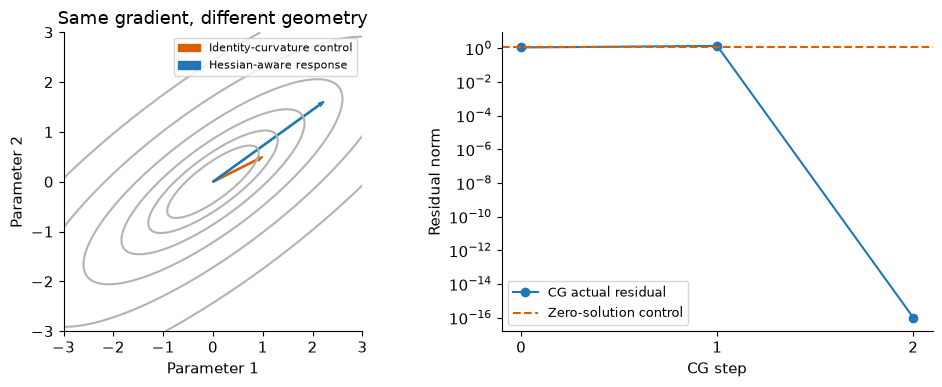

In [7]:
rotation = torch.tensor([[0.8, -0.6], [0.6, 0.8]], dtype=DTYPE)
H = rotation @ torch.diag(torch.tensor([0.4, 4.0], dtype=DTYPE)) @ rotation.T
g = torch.tensor([1.0, 0.5], dtype=DTYPE)
response, residuals = conjugate_gradient(lambda v: H @ v, g)
u, v = np.meshgrid(np.linspace(-3, 3, 150), np.linspace(-3, 3, 150))
points = torch.tensor(np.stack([u, v], -1), dtype=DTYPE)
energy = 0.5 * torch.einsum("...p,pq,...q->...", points, H, points)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].contour(u, v, energy.numpy(), levels=[0.25, 0.5, 1, 2, 4, 8], colors=".7")
for vector, label, color in [
    (g, "Identity-curvature control", "#d95f02"),
    (response, "Hessian-aware response", "#1f77b4"),
]:
    axes[0].arrow(
        0, 0, *vector.tolist(), width=0.025, color=color, length_includes_head=True, label=label
    )
axes[0].set(
    xlabel="Parameter 1",
    ylabel="Parameter 2",
    aspect="equal",
    title="Same gradient, different geometry",
)
axes[0].legend(fontsize=8)
axes[1].semilogy(
    range(len(residuals)), residuals.clamp_min(1e-16), "o-", label="CG actual residual"
)
axes[1].axhline(
    float(torch.linalg.vector_norm(g)), color="#d95f02", ls="--", label="Zero-solution control"
)
axes[1].set(xlabel="CG step", ylabel="Residual norm", xticks=range(len(residuals)))
axes[1].legend(fontsize=9)
show_figure(fig, "attribution_curvature_solve")


<details><summary>Interpretation — does a small residual prove the scientific approximation?</summary>

It proves that we solved this linear system accurately. It does not prove that
the fitted model is stationary, that its local Hessian describes a large change,
or that a checkpoint score predicts removal. We will check those questions with
separate experiments. The identity-curvature arrow shows what is lost if the
inverse Hessian is discarded.

</details>


### Exercise 5 — Actually refit the counterfactual models

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 25–35 minutes on this exercise.
```

Implement independent Newton refits from zero for every weight row. Use your weighted objective and
derivatives, an individual Armijo line search for each fit, and a strict maximum-coordinate gradient
tolerance. Preserve parameter states and residuals for plotting.

<details><summary>Help</summary>

Solve `H step = gradient`, then propose `theta - rate * step`. Halve only the rates of fits that
fail sufficient decrease. Freeze already converged rows. Near an optimum, predicted loss decreases
can be smaller than floating-point roundoff; permit eight machine epsilons times `max(1, abs(loss))`
in the comparison, while still requiring the original gradient tolerance. A common bug is reporting
convergence because the step became tiny.

</details>

<details><summary>Expected output</summary>

All counterfactual optima match independent SciPy root solves. Every final gradient is at most
1e-10, and a one-update budget fails. Batching must not turn several objectives into one pooled fit.

</details>

<details><summary>Solution</summary>

```python
def fit_weighted_logistic(
    x: Tensor,
    y: Tensor,
    weights: Tensor,
    l2: float = 0.02,
    tolerance: float = 1e-10,
    max_steps: int = 60,
) -> dict[str, Tensor]:
    """Independently refit every row of weights from zero using Newton/Armijo.

    Batching shares matrix operations, not fitted parameters or loss reductions.
    Each fit keeps its own line search and convergence decision. No failed fit is
    silently accepted. Regularization stays fixed after normalization of weights.
    """
    if weights.ndim != 2 or l2 <= 0 or not math.isfinite(l2):
        raise ValueError("Use weights [fits, examples] and a strictly positive regularizer.")
    if tolerance <= 0 or not math.isfinite(tolerance) or max_steps < 1:
        raise ValueError("Use a positive residual tolerance and iteration budget.")
    theta = torch.zeros(weights.shape[0], x.shape[1], dtype=x.dtype, device=x.device)
    states, residuals = [], []
    for _ in range(max_steps + 1):
        loss = weighted_objective(theta, x, y, weights, l2)
        gradient, hessian = objective_derivatives(theta, x, y, weights, l2)
        norms = torch.linalg.vector_norm(gradient, ord=float("inf"), dim=1)
        states.append(theta.clone())
        residuals.append(norms)
        active = norms > tolerance
        if not active.any():
            return {
                "theta": theta,
                "states": torch.stack(states),
                "gradient_norms": torch.stack(residuals),
                "objective": loss,
            }
        if len(states) > max_steps:
            break
        step = torch.linalg.solve(hessian, gradient.unsqueeze(-1)).squeeze(-1)
        step[~active] = 0
        decrement = (gradient * step).sum(1)
        rates = torch.ones(len(theta), dtype=x.dtype, device=x.device)
        accepted = ~active
        proposed = theta.clone()
        for _ in range(30):
            trial = theta - rates[:, None] * step
            trial_loss = weighted_objective(trial, x, y, weights, l2)
            # Near the optimum, the predicted decrease can be below one ulp.
            # Allow objective roundoff while still requiring the final gradient
            # tolerance; otherwise a vanishing step can stall a correct refit.
            roundoff = 8 * torch.finfo(x.dtype).eps * loss.abs().clamp_min(1)
            sufficient = trial_loss <= loss - 1e-4 * rates * decrement + roundoff
            newly_accepted = sufficient & ~accepted
            proposed[newly_accepted] = trial[newly_accepted]
            accepted |= sufficient
            if accepted.all():
                break
            rates[~accepted] *= 0.5
        if not accepted.all():
            raise RuntimeError(
                "Newton line search failed; retain the failure instead of accepting an unfinished refit."
            )
        theta = proposed
    raise RuntimeError(
        f"Newton did not converge for every fit; largest gradient is {float(norms.max()):.3g}."
    )
```

</details>


In [8]:
def fit_weighted_logistic(
    x: Tensor,
    y: Tensor,
    weights: Tensor,
    l2: float = 0.02,
    tolerance: float = 1e-10,
    max_steps: int = 60,
) -> dict[str, Tensor]:
    """Independently refit every row of weights from zero using Newton/Armijo.

    Batching shares matrix operations, not fitted parameters or loss reductions.
    Each fit keeps its own line search and convergence decision. No failed fit is
    silently accepted. Regularization stays fixed after normalization of weights.
    """
    if weights.ndim != 2 or l2 <= 0 or not math.isfinite(l2):
        raise ValueError("Use weights [fits, examples] and a strictly positive regularizer.")
    if tolerance <= 0 or not math.isfinite(tolerance) or max_steps < 1:
        raise ValueError("Use a positive residual tolerance and iteration budget.")
    theta = torch.zeros(weights.shape[0], x.shape[1], dtype=x.dtype, device=x.device)
    states, residuals = [], []
    for _ in range(max_steps + 1):
        loss = weighted_objective(theta, x, y, weights, l2)
        gradient, hessian = objective_derivatives(theta, x, y, weights, l2)
        norms = torch.linalg.vector_norm(gradient, ord=float("inf"), dim=1)
        states.append(theta.clone())
        residuals.append(norms)
        active = norms > tolerance
        if not active.any():
            return {
                "theta": theta,
                "states": torch.stack(states),
                "gradient_norms": torch.stack(residuals),
                "objective": loss,
            }
        if len(states) > max_steps:
            break
        step = torch.linalg.solve(hessian, gradient.unsqueeze(-1)).squeeze(-1)
        step[~active] = 0
        decrement = (gradient * step).sum(1)
        rates = torch.ones(len(theta), dtype=x.dtype, device=x.device)
        accepted = ~active
        proposed = theta.clone()
        for _ in range(30):
            trial = theta - rates[:, None] * step
            trial_loss = weighted_objective(trial, x, y, weights, l2)
            # Near the optimum, the predicted decrease can be below one ulp.
            # Allow objective roundoff while still requiring the final gradient
            # tolerance; otherwise a vanishing step can stall a correct refit.
            roundoff = 8 * torch.finfo(x.dtype).eps * loss.abs().clamp_min(1)
            sufficient = trial_loss <= loss - 1e-4 * rates * decrement + roundoff
            newly_accepted = sufficient & ~accepted
            proposed[newly_accepted] = trial[newly_accepted]
            accepted |= sufficient
            if accepted.all():
                break
            rates[~accepted] *= 0.5
        if not accepted.all():
            raise RuntimeError(
                "Newton line search failed; retain the failure instead of accepting an unfinished refit."
            )
        theta = proposed
    raise RuntimeError(
        f"Newton did not converge for every fit; largest gradient is {float(norms.max()):.3g}."
    )



tests.test_fit_weighted_logistic(fit_weighted_logistic)


All tests in test_fit_weighted_logistic passed!


## 4️⃣ Differentiate through an optimum

At a stationary optimum, $\nabla F(\hat\theta)=0$. Perturb the objective to
$F(\theta)+\epsilon q_i(\theta)$ and differentiate its stationarity equation:

$$H\frac{d\hat\theta}{d\epsilon}+\nabla q_i(\hat\theta)=0.$$

A query loss then has derivative

$$I_{\mathrm{up}}(i,q)=-\nabla\ell_q(\hat\theta)^T H^{-1}\nabla q_i(\hat\theta).$$

A positive number means that upweighting this training row increases the query
loss. For a first-order removal estimate, multiply by $-1/n$. That removal loss
change is positive for a helpful example. Write the sign convention beside your
plot; otherwise two equivalent analyses can appear to disagree.

This is the local calculation in [Koh and Liang (2017)](https://proceedings.mlr.press/v70/koh17a.html).
Our queries and counterfactuals below are a new teaching example.


### Exercise 6 — Compute the signed influence matrix

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 15–20 minutes on this exercise.
```

Return influence shaped `[training examples, queries]`. Solve for the query directions once, then
dot them with every training gradient. Support nonnegative added damping, but do not claim damping
leaves the exact derivative unchanged.

<details><summary>Help</summary>

Use a linear solve rather than an explicit matrix inverse. Check symmetry and positive definiteness.
A common sign error is forgetting the leading minus: this function returns the derivative under
upweighting, not a helpfulness score.

</details>

<details><summary>Expected output</summary>

The predictions match central differences of independent exact quadratic optima, including both signs and unequal training/query counts.

</details>

<details><summary>Solution</summary>

```python
def upweight_influence(
    hessian: Tensor, train_gradients: Tensor, query_gradients: Tensor, damping: float = 0.0
) -> Tensor:
    """d(query loss)/d epsilon for F + epsilon * one regularized training loss."""
    p = hessian.shape[0]
    if hessian.shape != (p, p) or train_gradients.ndim != 2 or query_gradients.ndim != 2:
        raise ValueError("Use a square Hessian and two example-by-parameter gradient matrices.")
    if train_gradients.shape[1] != p or query_gradients.shape[1] != p:
        raise ValueError("Every gradient must refer to the same parameter coordinates.")
    if not math.isfinite(damping) or damping < 0:
        raise ValueError("Damping must be finite and nonnegative.")
    if not torch.allclose(hessian, hessian.T, rtol=1e-10, atol=1e-12):
        raise ValueError("The objective Hessian must be symmetric.")
    system = hessian + damping * torch.eye(p, dtype=hessian.dtype, device=hessian.device)
    torch.linalg.cholesky(system)  # Fail explicitly if the local SPD premise fails.
    response = torch.linalg.solve(system, query_gradients.T)
    return -train_gradients @ response
```

</details>


In [9]:
def upweight_influence(
    hessian: Tensor, train_gradients: Tensor, query_gradients: Tensor, damping: float = 0.0
) -> Tensor:
    """d(query loss)/d epsilon for F + epsilon * one regularized training loss."""
    p = hessian.shape[0]
    if hessian.shape != (p, p) or train_gradients.ndim != 2 or query_gradients.ndim != 2:
        raise ValueError("Use a square Hessian and two example-by-parameter gradient matrices.")
    if train_gradients.shape[1] != p or query_gradients.shape[1] != p:
        raise ValueError("Every gradient must refer to the same parameter coordinates.")
    if not math.isfinite(damping) or damping < 0:
        raise ValueError("Damping must be finite and nonnegative.")
    if not torch.allclose(hessian, hessian.T, rtol=1e-10, atol=1e-12):
        raise ValueError("The objective Hessian must be symmetric.")
    system = hessian + damping * torch.eye(p, dtype=hessian.dtype, device=hessian.device)
    torch.linalg.cholesky(system)  # Fail explicitly if the local SPD premise fails.
    response = torch.linalg.solve(system, query_gradients.T)
    return -train_gradients @ response



tests.test_upweight_influence(upweight_influence)


All tests in test_upweight_influence passed!


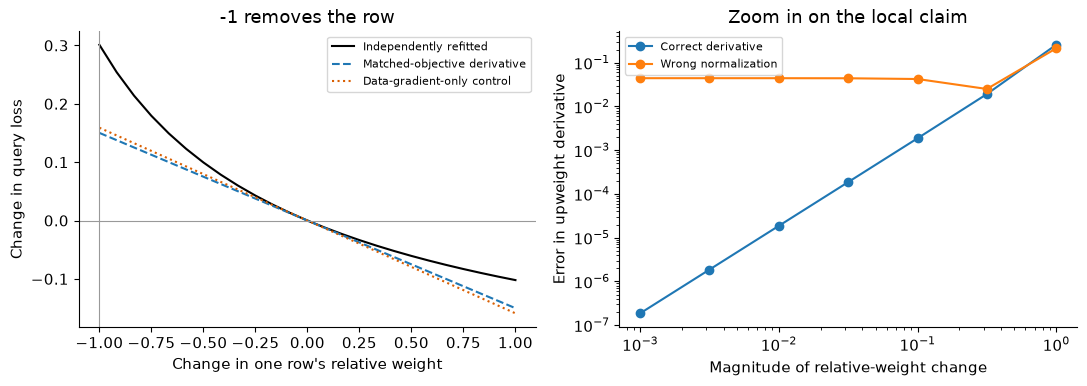

All tests in test_regularized_removal_normalization passed!


In [10]:
small_x = torch.tensor(
    [[1.0, 0.0, 1.0], [0.0, 2.0, 1.0], [-1.0, 1.0, 1.0], [2.0, -1.0, 1.0], [0.3, 0.8, 1.0]],
    dtype=DTYPE,
)
small_y = torch.tensor([1.0, 0.0, 0.0, 1.0, 1.0], dtype=DTYPE)
n = len(small_x)
l2 = 0.3
base = fit_weighted_logistic(small_x, small_y, torch.ones(1, n, dtype=DTYPE), l2)
theta = base["theta"][0]
_, hs = objective_derivatives(theta[None], small_x, small_y, torch.ones(1, n, dtype=DTYPE), l2)
qx = torch.tensor([[0.2, 1.4, 1.0]], dtype=DTYPE)
qy = torch.zeros(1, dtype=DTYPE)
g_query = logistic_gradients(theta, qx, qy)
g_full = logistic_gradients(theta, small_x, small_y, l2)
g_raw = logistic_gradients(theta, small_x, small_y)
influence = upweight_influence(hs[0], g_full, g_query)[:, 0]
wrong_normalization = upweight_influence(hs[0], g_raw, g_query)[:, 0]
strengths = torch.linspace(-1, 1, 25, dtype=DTYPE)
example = 1
weights = torch.ones(len(strengths), n, dtype=DTYPE)
weights[:, example] += strengths
refits = fit_weighted_logistic(small_x, small_y, weights, l2)
actual_loss = F.softplus(refits["theta"] @ qx.T).flatten()
base_loss = logistic_losses(theta, qx, qy)[0]
actual_change = actual_loss - base_loss
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(strengths, actual_change, color="black", label="Independently refitted")
axes[0].plot(
    strengths, strengths / n * influence[example], "--", label="Matched-objective derivative"
)
axes[0].plot(
    strengths,
    strengths / n * wrong_normalization[example],
    ":",
    color="#d95f02",
    label="Data-gradient-only control",
)
axes[0].axhline(0, color=".6", lw=0.8)
axes[0].axvline(-1, color=".6", lw=0.8)
axes[0].set(
    xlabel="Change in one row's relative weight",
    ylabel="Change in query loss",
    title="-1 removes the row",
)
axes[0].legend(fontsize=8)
probe_strengths = torch.logspace(-3, 0, 7, dtype=DTYPE)
probe_weights = torch.ones(2 * len(probe_strengths), n, dtype=DTYPE)
probe_weights[: len(probe_strengths), example] -= probe_strengths
probe_weights[len(probe_strengths) :, example] += probe_strengths
probe_refits = fit_weighted_logistic(small_x, small_y, probe_weights, l2)
probe_losses = F.softplus(probe_refits["theta"] @ qx.T).flatten()
measured_derivative = (
    probe_losses[len(probe_strengths) :] - probe_losses[: len(probe_strengths)]
) / (2 * probe_strengths / n)
for label, value in [
    ("Correct derivative", influence[example]),
    ("Wrong normalization", wrong_normalization[example]),
]:
    axes[1].loglog(
        probe_strengths, (measured_derivative - value).abs().clamp_min(1e-12), "o-", label=label
    )
axes[1].set(
    xlabel="Magnitude of relative-weight change",
    ylabel="Error in upweight derivative",
    title="Zoom in on the local claim",
)
axes[1].legend(fontsize=8)
show_figure(fig, "attribution_weight_perturbation")
tests.test_regularized_removal_normalization()


<details><summary>Interpretation — why is the orange control different even near zero?</summary>

The solid line refits the normalized weighted objective with the same penalty.
Its infinitesimal direction includes the regularizer in the perturbed row.
The orange derivative instead upweights only its data loss. It differentiates a
different objective. Matching that derivative perfectly would still fail to
answer this experiment's question. Farther from zero, even the correctly matched
linear approximation has curvature error; the actual refits show its size.

</details>

## 5️⃣ Follow what happened during training

An optimum-based derivative does not explain the particular training trajectory.
For single-example SGD, every update has an identifiable training row. Assign
its observed query-loss reduction to that row. The assignments telescope to
the total reduction from initialization to the final state.

This exact accounting is the starting point for
[TracIn](https://proceedings.neurips.cc/paper/2020/hash/e6385d39ec9394f2f3a354d9d2b88eec-Abstract.html).
A positive score means the training visits reduced the specified query loss.
It does not mean removing the example and retraining must increase that loss.


### Exercise 7 — Record the optimization path

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 15–20 minutes on this exercise.
```

Implement single-example SGD, preserving the zero initialization, every following state, the exact
row visitation order and the learning rate for every update. Validate that each epoch is a
permutation of the training rows.

<details><summary>Help</summary>

An epoch learning rate is repeated once per training example. Apply the gradient of the regularized
row loss. Common mistake: storing only the state after each update, which loses the first observed
loss reduction.

</details>

<details><summary>Expected output</summary>

Every stored state matches an independent autograd training loop. An invalid epoch permutation fails.

</details>

<details><summary>Solution</summary>

```python
def sgd_trace(
    x: Tensor, y: Tensor, orders: Tensor, epoch_rates: Tensor, l2: float
) -> dict[str, Tensor]:
    """Record the actual single-example optimization path, starting at zero."""
    if orders.ndim != 2 or orders.shape[1] != len(x) or epoch_rates.shape != (len(orders),):
        raise ValueError("Provide one permutation and one learning rate for every epoch.")
    expected = torch.arange(len(x), device=orders.device).expand_as(orders)
    if not torch.equal(orders.sort(dim=1).values, expected):
        raise ValueError("Each epoch must visit every training example exactly once.")
    if not torch.isfinite(epoch_rates).all() or (epoch_rates <= 0).any():
        raise ValueError("Epoch learning rates must be finite and strictly positive.")
    used_ids = orders.flatten()
    rates = epoch_rates.repeat_interleave(len(x))
    states = torch.zeros(len(used_ids) + 1, x.shape[1], dtype=x.dtype, device=x.device)
    with torch.no_grad():
        for t, index in enumerate(used_ids.tolist()):
            gradient = logistic_gradients(
                states[t], x[index : index + 1], y[index : index + 1], l2
            )[0]
            states[t + 1] = states[t] - rates[t] * gradient
    return {"states": states, "used_ids": used_ids, "rates": rates}
```

</details>


In [11]:
def sgd_trace(
    x: Tensor, y: Tensor, orders: Tensor, epoch_rates: Tensor, l2: float
) -> dict[str, Tensor]:
    """Record the actual single-example optimization path, starting at zero."""
    if orders.ndim != 2 or orders.shape[1] != len(x) or epoch_rates.shape != (len(orders),):
        raise ValueError("Provide one permutation and one learning rate for every epoch.")
    expected = torch.arange(len(x), device=orders.device).expand_as(orders)
    if not torch.equal(orders.sort(dim=1).values, expected):
        raise ValueError("Each epoch must visit every training example exactly once.")
    if not torch.isfinite(epoch_rates).all() or (epoch_rates <= 0).any():
        raise ValueError("Epoch learning rates must be finite and strictly positive.")
    used_ids = orders.flatten()
    rates = epoch_rates.repeat_interleave(len(x))
    states = torch.zeros(len(used_ids) + 1, x.shape[1], dtype=x.dtype, device=x.device)
    with torch.no_grad():
        for t, index in enumerate(used_ids.tolist()):
            gradient = logistic_gradients(
                states[t], x[index : index + 1], y[index : index + 1], l2
            )[0]
            states[t + 1] = states[t] - rates[t] * gradient
    return {"states": states, "used_ids": used_ids, "rates": rates}



tests.test_sgd_trace(sgd_trace)


All tests in test_sgd_trace passed!


### Exercise 8 — Attribute actual and first-order loss reductions

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 20–30 minutes on this exercise.
```

Return exact and first-order scores for every training-row/query pair, plus all per-step values.
Include the full update gradient in the approximation. Also return a raw-data-gradient-only control.
Check that the supplied states really follow the stated SGD updates.

<details><summary>Help</summary>

The Taylor loss reduction is $\eta_t\nabla\ell_q(\theta_t)^T\nabla q_i(\theta_t)$. For a logistic
query, its gradient is its residual times its input, so you can avoid storing a `[steps, queries,
parameters]` tensor. Use `index_add_` to sum visits into their actual training rows. Exact minibatch
allocation is a different problem; do not silently split exact loss equally across a batch.

</details>

<details><summary>Expected output</summary>

Exact scores telescope separately for each query. First-order steps match autograd products.
Changing the chunk size preserves every score; a tampered trajectory fails.

</details>

<details><summary>Solution</summary>

```python
def trace_loss_reductions(
    states: Tensor,
    used_ids: Tensor,
    rates: Tensor,
    train_x: Tensor,
    train_y: Tensor,
    query_x: Tensor,
    query_y: Tensor,
    l2: float,
    chunk_size: int = 128,
) -> dict[str, Tensor]:
    """Actual loss accounting and its Taylor approximation along recorded SGD.

    The exact allocation is well-defined here because each update uses one row.
    The calculation includes that update's regularizer contribution. The raw-only
    control deliberately omits it. No tensor of per-step per-query full gradients
    is needed: a logistic query gradient is its residual times its input vector.
    """
    steps = len(used_ids)
    if states.ndim != 2 or len(states) != steps + 1 or rates.shape != (steps,):
        raise ValueError("Every update needs a before/after state, training ID and learning rate.")
    if used_ids.dtype != torch.int64 or (used_ids < 0).any() or (used_ids >= len(train_x)).any():
        raise ValueError("Recorded training IDs must be valid integer row indices.")
    if chunk_size < 1 or not torch.isfinite(rates).all() or (rates <= 0).any():
        raise ValueError("Use a positive chunk size and positive finite learning rates.")
    exact_steps, first_order_steps, raw_steps = [], [], []
    for start in range(0, steps, chunk_size):
        stop = min(start + chunk_size, steps)
        before, after = states[start:stop], states[start + 1 : stop + 1]
        x = train_x[used_ids[start:stop]]
        y = train_y[used_ids[start:stop]]
        raw_gradient = (torch.sigmoid((before * x).sum(1)) - y)[:, None] * x
        gradient = raw_gradient + l2 * before
        if not torch.allclose(
            after - before, -rates[start:stop, None] * gradient, rtol=1e-9, atol=1e-12
        ):
            raise ValueError("Recorded states do not follow the stated single-example SGD update.")
        before_logits, after_logits = before @ query_x.T, after @ query_x.T
        before_loss = F.softplus(before_logits) - query_y[None, :] * before_logits
        after_loss = F.softplus(after_logits) - query_y[None, :] * after_logits
        query_residual = torch.sigmoid(before_logits) - query_y[None, :]
        exact_steps.append(before_loss - after_loss)
        first_order_steps.append(rates[start:stop, None] * query_residual * (gradient @ query_x.T))
        raw_steps.append(rates[start:stop, None] * query_residual * (raw_gradient @ query_x.T))
    exact_steps = torch.cat(exact_steps)
    first_order_steps = torch.cat(first_order_steps)
    raw_steps = torch.cat(raw_steps)
    shape = (len(train_x), len(query_x))

    def collect(values):
        return torch.zeros(shape, dtype=states.dtype, device=states.device).index_add_(
            0, used_ids, values
        )

    return {
        "exact": collect(exact_steps),
        "first_order": collect(first_order_steps),
        "raw_only": collect(raw_steps),
        "exact_steps": exact_steps,
        "first_order_steps": first_order_steps,
        "raw_only_steps": raw_steps,
    }
```

</details>


In [12]:
def trace_loss_reductions(
    states: Tensor,
    used_ids: Tensor,
    rates: Tensor,
    train_x: Tensor,
    train_y: Tensor,
    query_x: Tensor,
    query_y: Tensor,
    l2: float,
    chunk_size: int = 128,
) -> dict[str, Tensor]:
    """Actual loss accounting and its Taylor approximation along recorded SGD.

    The exact allocation is well-defined here because each update uses one row.
    The calculation includes that update's regularizer contribution. The raw-only
    control deliberately omits it. No tensor of per-step per-query full gradients
    is needed: a logistic query gradient is its residual times its input vector.
    """
    steps = len(used_ids)
    if states.ndim != 2 or len(states) != steps + 1 or rates.shape != (steps,):
        raise ValueError("Every update needs a before/after state, training ID and learning rate.")
    if used_ids.dtype != torch.int64 or (used_ids < 0).any() or (used_ids >= len(train_x)).any():
        raise ValueError("Recorded training IDs must be valid integer row indices.")
    if chunk_size < 1 or not torch.isfinite(rates).all() or (rates <= 0).any():
        raise ValueError("Use a positive chunk size and positive finite learning rates.")
    exact_steps, first_order_steps, raw_steps = [], [], []
    for start in range(0, steps, chunk_size):
        stop = min(start + chunk_size, steps)
        before, after = states[start:stop], states[start + 1 : stop + 1]
        x = train_x[used_ids[start:stop]]
        y = train_y[used_ids[start:stop]]
        raw_gradient = (torch.sigmoid((before * x).sum(1)) - y)[:, None] * x
        gradient = raw_gradient + l2 * before
        if not torch.allclose(
            after - before, -rates[start:stop, None] * gradient, rtol=1e-9, atol=1e-12
        ):
            raise ValueError("Recorded states do not follow the stated single-example SGD update.")
        before_logits, after_logits = before @ query_x.T, after @ query_x.T
        before_loss = F.softplus(before_logits) - query_y[None, :] * before_logits
        after_loss = F.softplus(after_logits) - query_y[None, :] * after_logits
        query_residual = torch.sigmoid(before_logits) - query_y[None, :]
        exact_steps.append(before_loss - after_loss)
        first_order_steps.append(rates[start:stop, None] * query_residual * (gradient @ query_x.T))
        raw_steps.append(rates[start:stop, None] * query_residual * (raw_gradient @ query_x.T))
    exact_steps = torch.cat(exact_steps)
    first_order_steps = torch.cat(first_order_steps)
    raw_steps = torch.cat(raw_steps)
    shape = (len(train_x), len(query_x))

    def collect(values):
        return torch.zeros(shape, dtype=states.dtype, device=states.device).index_add_(
            0, used_ids, values
        )

    return {
        "exact": collect(exact_steps),
        "first_order": collect(first_order_steps),
        "raw_only": collect(raw_steps),
        "exact_steps": exact_steps,
        "first_order_steps": first_order_steps,
        "raw_only_steps": raw_steps,
    }



tests.test_trace_loss_reductions(trace_loss_reductions)


All tests in test_trace_loss_reductions passed!


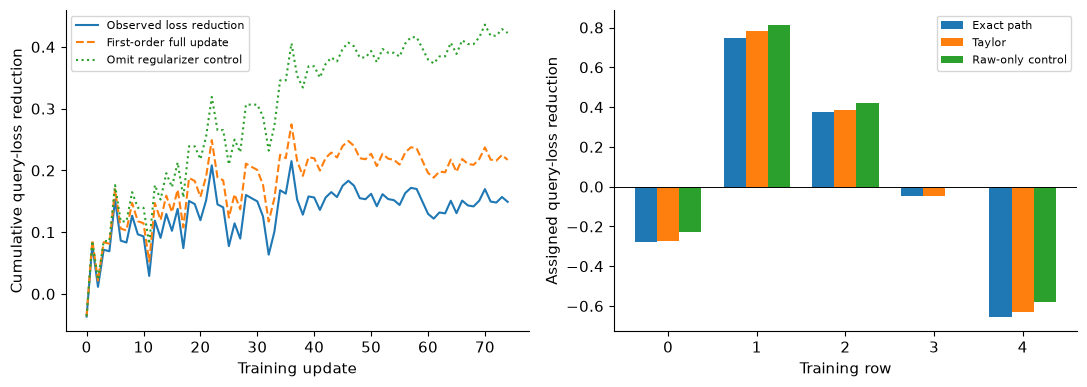

In [13]:
orders = torch.stack(
    [torch.randperm(n, generator=torch.Generator().manual_seed(100 + epoch)) for epoch in range(15)]
)
epoch_rates = torch.cat([torch.full((8,), 0.12, dtype=DTYPE), torch.full((7,), 0.04, dtype=DTYPE)])
trace = sgd_trace(small_x, small_y, orders, epoch_rates, 0.3)
path_scores = trace_loss_reductions(
    trace["states"], trace["used_ids"], trace["rates"], small_x, small_y, qx, qy, 0.3
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for key, label, style in [
    ("exact_steps", "Observed loss reduction", "-"),
    ("first_order_steps", "First-order full update", "--"),
    ("raw_only_steps", "Omit regularizer control", ":"),
]:
    axes[0].plot(torch.cumsum(path_scores[key][:, 0], 0), style, label=label)
axes[0].set(xlabel="Training update", ylabel="Cumulative query-loss reduction")
axes[0].legend(fontsize=8)
pos = np.arange(n)
for offset, key, label in [
    (-0.25, "exact", "Exact path"),
    (0, "first_order", "Taylor"),
    (0.25, "raw_only", "Raw-only control"),
]:
    axes[1].bar(pos + offset, path_scores[key][:, 0], width=0.25, label=label)
axes[1].axhline(0, color="black", lw=0.7)
axes[1].set(xlabel="Training row", ylabel="Assigned query-loss reduction", xticks=pos)
axes[1].legend(fontsize=8)
show_figure(fig, "attribution_exact_training_path")


## 6️⃣ Replace a long path with saved checkpoints

TracInCP replaces gradients at actual visits by gradients evaluated at selected
checkpoints. It sums learning-rate-weighted products across those checkpoints.
It does not preserve exact telescoping, and a checkpoint subset does not account
for training visits that it omits. We will retain early, late, all and last-only
choices instead of choosing whichever agrees best with final outcomes.


### Exercise 9 — Compute TracInCP scores

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 10–15 minutes on this exercise.
```

Take training gradients `[checkpoints, training examples, parameters]`, query gradients with the
analogous query axis, and a vector of checkpoint learning rates. Return the weighted score for each
training/query pair.

<details><summary>Help</summary>

Multiply gradient matrices within the same checkpoint, weight that checkpoint, then sum. Common
mistakes: pairing gradients from different checkpoints, averaging away the learning-rate scale, and
treating a checkpoint heuristic as an exact observed loss reduction.

</details>

<details><summary>Expected output</summary>

The hand-computed unequal-axis example returns [[1.2, 2.4], [-2.1, 1.9], [-0.2, 1.9]]. Reordering
checkpoints with their rates leaves the answer unchanged.

</details>

<details><summary>Solution</summary>

```python
def tracin_checkpoint_scores(
    train_gradients: Tensor, query_gradients: Tensor, rates: Tensor
) -> Tensor:
    """Weighted gradient products; positive means first-order loss reduction.

    The input is [checkpoints, examples, parameters]. Rates are actual checkpoint
    learning-rate weights. A checkpoint subset covers only its selected visits;
    this function does not rescale scores to pretend they sum to observed loss.
    """
    if train_gradients.ndim != 3 or query_gradients.ndim != 3:
        raise ValueError("Keep checkpoint, example and parameter axes distinct.")
    k, _, p = train_gradients.shape
    if (
        query_gradients.shape[0] != k
        or query_gradients.shape[2] != p
        or rates.shape != (k,)
        or k == 0
    ):
        raise ValueError("Checkpoint counts, parameter coordinates and rate counts must match.")
    if not torch.isfinite(rates).all() or (rates < 0).any():
        raise ValueError("Use finite nonnegative learning-rate weights.")
    return torch.einsum("knp,kqp,k->nq", train_gradients, query_gradients, rates)
```

</details>


In [14]:
def tracin_checkpoint_scores(
    train_gradients: Tensor, query_gradients: Tensor, rates: Tensor
) -> Tensor:
    """Weighted gradient products; positive means first-order loss reduction.

    The input is [checkpoints, examples, parameters]. Rates are actual checkpoint
    learning-rate weights. A checkpoint subset covers only its selected visits;
    this function does not rescale scores to pretend they sum to observed loss.
    """
    if train_gradients.ndim != 3 or query_gradients.ndim != 3:
        raise ValueError("Keep checkpoint, example and parameter axes distinct.")
    k, _, p = train_gradients.shape
    if (
        query_gradients.shape[0] != k
        or query_gradients.shape[2] != p
        or rates.shape != (k,)
        or k == 0
    ):
        raise ValueError("Checkpoint counts, parameter coordinates and rate counts must match.")
    if not torch.isfinite(rates).all() or (rates < 0).any():
        raise ValueError("Use finite nonnegative learning-rate weights.")
    return torch.einsum("knp,kqp,k->nq", train_gradients, query_gradients, rates)



tests.test_tracin_checkpoint_scores(tracin_checkpoint_scores)


All tests in test_tracin_checkpoint_scores passed!


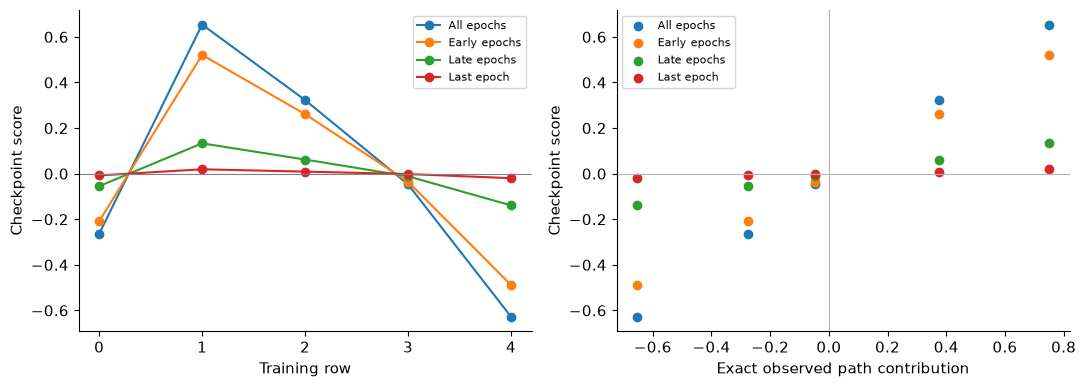

In [15]:
checkpoint_theta = trace["states"][n::n]
train_gradients = torch.stack(
    [logistic_gradients(t, small_x, small_y, 0.3) for t in checkpoint_theta]
)
query_gradients = torch.stack([logistic_gradients(t, qx, qy) for t in checkpoint_theta])
choices = {
    "All epochs": slice(None),
    "Early epochs": slice(0, 8),
    "Late epochs": slice(8, None),
    "Last epoch": slice(-1, None),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, selected in choices.items():
    scores = tracin_checkpoint_scores(
        train_gradients[selected], query_gradients[selected], epoch_rates[selected]
    )[:, 0]
    axes[0].plot(pos, scores, "o-", label=label)
    axes[1].scatter(path_scores["exact"][:, 0], scores, label=label)
axes[0].axhline(0, color=".5", lw=0.8)
axes[0].set(xlabel="Training row", ylabel="Checkpoint score", xticks=pos)
axes[0].legend(fontsize=8)
axes[1].axhline(0, color=".7", lw=0.8)
axes[1].axvline(0, color=".7", lw=0.8)
axes[1].set(xlabel="Exact observed path contribution", ylabel="Checkpoint score")
axes[1].legend(fontsize=8)
show_figure(fig, "attribution_checkpoint_choices")


<details><summary>Interpretation — why are these not all on the diagonal?</summary>

The checkpoint calculation evaluates a training row at an epoch endpoint instead
of its actual visit. Early-only and late-only scores cover different pieces of
training; last-only uses just one checkpoint. The exact path uses the observed
updates. Similar rankings can be useful even when scales differ, but neither
ranking agreement nor a scatter correlation establishes an exact deletion effect.

</details>

## 7️⃣ A faster gradient product for an affine layer

For one affine invocation, a weight gradient is an outer product of a
preactivation derivative and an input. Its dot product with another example's
weight gradient factors into two much smaller dot products. The bias contributes
one additional preactivation-gradient dot product. This is the gradient-product
identity behind a useful memory saving; derive it before implementing it.

A tied layer applied at several token positions has a sum of outer products.
Its product contains all cross-position terms. The one-invocation identity below
must not be applied to it by summing only matching positions.


### Exercise 10 — Compute the affine gradient product without flattening it

```text
Difficulty: 🔴🔴🔴⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 10–15 minutes on this exercise.
```

Return all left-example/right-example gradient dot products using only layer inputs and
preactivation derivatives. Support bias and bias-free affine layers. This exercise concerns the
layer data-loss gradients; shared regularizers are separate contributions.

<details><summary>Help</summary>

Use $\langle\delta a^T,\delta\prime a\prime^T\rangle=(\delta^T\delta\prime)(a^Ta\prime)$. With a
bias, add one to the input dot product before multiplying. Common mistake: adding the two factor
products instead of multiplying them.

</details>

<details><summary>Expected output</summary>

Both bias settings match full autograd gradients through a nonlinear loss. Unequal numbers of
examples on the two sides prevent an accidental elementwise shortcut.

</details>

<details><summary>Solution</summary>

```python
def ghost_linear_products(
    left_inputs: Tensor,
    left_deltas: Tensor,
    right_inputs: Tensor,
    right_deltas: Tensor,
    bias: bool = True,
) -> Tensor:
    """Exact gradient products for one affine layer with one invocation per example.

    Deltas differentiate scalar losses with respect to preactivations. This is not
    a formula for tied parameters used at several token positions; those require
    all pairs of positions. Shared regularizers are also separate gradient terms.
    """
    arrays = (left_inputs, left_deltas, right_inputs, right_deltas)
    if any(a.ndim != 2 for a in arrays):
        raise ValueError("Inputs and preactivation derivatives must be two-dimensional.")
    if len(left_inputs) != len(left_deltas) or len(right_inputs) != len(right_deltas):
        raise ValueError("Every example needs its own input and preactivation derivative.")
    if (
        left_inputs.shape[1] != right_inputs.shape[1]
        or left_deltas.shape[1] != right_deltas.shape[1]
    ):
        raise ValueError("Both sides must describe the same affine layer.")
    return (left_inputs @ right_inputs.T + int(bias)) * (left_deltas @ right_deltas.T)
```

</details>


In [16]:
def ghost_linear_products(
    left_inputs: Tensor,
    left_deltas: Tensor,
    right_inputs: Tensor,
    right_deltas: Tensor,
    bias: bool = True,
) -> Tensor:
    """Exact gradient products for one affine layer with one invocation per example.

    Deltas differentiate scalar losses with respect to preactivations. This is not
    a formula for tied parameters used at several token positions; those require
    all pairs of positions. Shared regularizers are also separate gradient terms.
    """
    arrays = (left_inputs, left_deltas, right_inputs, right_deltas)
    if any(a.ndim != 2 for a in arrays):
        raise ValueError("Inputs and preactivation derivatives must be two-dimensional.")
    if len(left_inputs) != len(left_deltas) or len(right_inputs) != len(right_deltas):
        raise ValueError("Every example needs its own input and preactivation derivative.")
    if (
        left_inputs.shape[1] != right_inputs.shape[1]
        or left_deltas.shape[1] != right_deltas.shape[1]
    ):
        raise ValueError("Both sides must describe the same affine layer.")
    return (left_inputs @ right_inputs.T + int(bias)) * (left_deltas @ right_deltas.T)



tests.test_ghost_linear_products(ghost_linear_products)


All tests in test_ghost_linear_products passed!


## Try It Yourself — make the first-order approximation fail

Change the learning-rate multiplier below. Predict what happens to the Taylor
error and whether the helpful/harmful assignment can change. This reruns training
and loss accounting; the exact path remains the control. Keep a stable small-step
case beside the larger step. A large mismatch is an outcome to explain.

Then change `query_row` or flip `query_label`. The image is not intrinsically
helpful: its assigned effect depends on the question asked of the model.


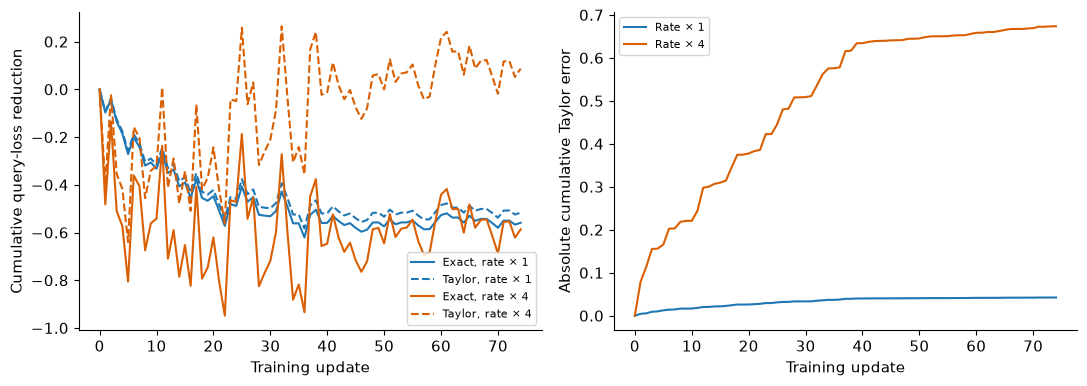

In [17]:
learning_rate_multiplier = 4.0
query_row = 2
query_label = 1.0
play_x = small_x[query_row : query_row + 1]
play_y = torch.tensor([query_label], dtype=DTYPE)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for multiplier, color in [(1.0, "#1f77b4"), (learning_rate_multiplier, "#d95f02")]:
    changed_trace = sgd_trace(small_x, small_y, orders, epoch_rates * multiplier, 0.3)
    changed_scores = trace_loss_reductions(
        changed_trace["states"],
        changed_trace["used_ids"],
        changed_trace["rates"],
        small_x,
        small_y,
        play_x,
        play_y,
        0.3,
    )
    exact = changed_scores["exact_steps"][:, 0].cumsum(0)
    linear = changed_scores["first_order_steps"][:, 0].cumsum(0)
    axes[0].plot(exact, color=color, label=f"Exact, rate × {multiplier:g}")
    axes[0].plot(linear, "--", color=color, label=f"Taylor, rate × {multiplier:g}")
    axes[1].plot((exact - linear).abs(), color=color, label=f"Rate × {multiplier:g}")
axes[0].set(xlabel="Training update", ylabel="Cumulative query-loss reduction")
axes[1].set(xlabel="Training update", ylabel="Absolute cumulative Taylor error")
for ax in axes:
    ax.legend(fontsize=8)
show_figure(fig, "attribution_step_size_play")


## 8️⃣ Move from five rows to real training images

The small examples isolate the mathematics. Now keep the methods fixed and test
their predictions on the UCI digits shown at the start. We use a binary logistic
classifier with 64 pixel coordinates and a bias. It is small enough to refit
every leave-one-out counterfactual, so an approximate ranking can be checked
against what a newly trained model actually does.

The source training/test files were collected from different groups of writers.
We use 128 source-training images to fit, another 48 to choose deletion policies,
and 64 source-test images for the final comparison. Individual writer IDs are
unavailable, so this is not a new per-writer study. Pixel counts are divided by
sixteen; we fit no normalization using the query sets.

Run both the clean-label and twelve-flipped-label conditions. All settings below
were specified before digit-model evaluation. In particular, final labels do not
choose a checkpoint, a seed, a deletion policy or a displayed query. The final
gallery uses the first two retained source rows per class.

We keep two definitions of training separate: a converged regularized optimum
for influence and leave-one-out, and the actual finite SGD paths for TracIn. A
comparison between their rankings is useful, but it does not make them estimates
of the same mathematical quantity.


In [18]:
import json
import tempfile
from types import SimpleNamespace
from scipy.stats import rankdata

L2 = 0.02
ORDER_SEEDS = (0, 1, 2)
RANDOM_SEEDS = tuple(range(1000, 1032))
BUDGETS = (2, 4, 8, 16, 32)
DAMPING = (0.0, 0.01, 0.1, 1.0)
STRENGTHS = (-1.0, -0.5, -0.1, -0.01, 0.01, 0.1, 0.5, 1.0)
CHECKPOINT_CHOICES = {
    "all": slice(None),
    "early": slice(0, 20),
    "late": slice(20, None),
    "last": slice(-1, None),
}


### Exercise 11 — Choose removals with the same class balance

```text
Difficulty: 🔴🔴⚪⚪⚪
Importance: 🔵🔵🔵🔵⚪

You should spend 10–15 minutes on this exercise.
```

A deletion policy can appear useful just by changing class proportions. Implement
a matched comparison: remove the lowest helpfulness scores, with exactly half
of an even budget from each observed training class. Keep source-row order when
scores tie. Here, observed means the label actually supplied during training.

<details><summary>Help</summary>

Find row indices separately for labels zero and one, stably sort the corresponding
scores, then take half the budget from each group. Return the selected row indices
in increasing order. A common mistake is matching true labels after corruption;
that gives the policy information it would not ordinarily have.

</details>

<details><summary>Expected output</summary>

The test's budget-two selection is [1, 4]. Budget four gives [1, 2, 4, 5]. An odd
budget or one that exceeds a class's available rows fails explicitly.

</details>

<details><summary>Solution</summary>

```python
def class_matched_removals(helpfulness: Tensor, labels: Tensor, budget: int) -> Tensor:
    """Select low helpfulness, with equal observed-class counts and stable ties."""
    if (
        helpfulness.ndim != 1
        or labels.shape != helpfulness.shape
        or not torch.isfinite(helpfulness).all()
    ):
        raise ValueError(
            "Provide one finite helpfulness score and observed label per training row."
        )
    if not ((labels == 0) | (labels == 1)).all() or budget < 0 or budget % 2:
        raise ValueError("Binary class matching requires an even nonnegative deletion budget.")
    selected = []
    for label in (0, 1):
        ids = torch.nonzero(labels == label).flatten()
        if len(ids) < budget // 2:
            raise ValueError("The budget exceeds the available rows in an observed class.")
        order = torch.argsort(helpfulness[ids], stable=True)
        selected.append(ids[order[: budget // 2]])
    return torch.cat(selected).sort().values
```

</details>


In [19]:
def class_matched_removals(helpfulness: Tensor, labels: Tensor, budget: int) -> Tensor:
    """Select low helpfulness, with equal observed-class counts and stable ties."""
    if (
        helpfulness.ndim != 1
        or labels.shape != helpfulness.shape
        or not torch.isfinite(helpfulness).all()
    ):
        raise ValueError(
            "Provide one finite helpfulness score and observed label per training row."
        )
    if not ((labels == 0) | (labels == 1)).all() or budget < 0 or budget % 2:
        raise ValueError("Binary class matching requires an even nonnegative deletion budget.")
    selected = []
    for label in (0, 1):
        ids = torch.nonzero(labels == label).flatten()
        if len(ids) < budget // 2:
            raise ValueError("The budget exceeds the available rows in an observed class.")
        order = torch.argsort(helpfulness[ids], stable=True)
        selected.append(ids[order[: budget // 2]])
    return torch.cat(selected).sort().values



tests.test_class_matched_removals(class_matched_removals)


All tests in test_class_matched_removals passed!


### Evaluate a fitted classifier and a retrieval control

These short helpers expose the quantities plotted below. Query loss is binary
cross entropy without a penalty term. Accuracy uses the model's zero-logit
threshold; it can stay unchanged while prediction confidence deteriorates.
The pixel baseline compares the actual images and their supplied labels. The
constant bias coordinate must not create image resemblance.


In [20]:
def query_outputs(theta, queries):
    """Actual classifier probabilities and unreduced query losses for each fit."""
    logits = theta @ queries["x"].T
    losses = F.softplus(logits) - queries["y"][None, :] * logits
    return {
        "logits": logits,
        "probabilities": torch.sigmoid(logits),
        "losses": losses,
        "correct": (logits >= 0) == queries["y"][None, :].bool(),
    }


def signed_pixel_similarity(train, train_y, queries):
    """A labelled image-retrieval control, without model loss or curvature."""
    pixels = F.normalize(train["x"][:, :-1], dim=1)
    query_pixels = F.normalize(queries["x"][:, :-1], dim=1)
    agreement = (2 * train_y[:, None] - 1) * (2 * queries["y"][None, :] - 1)
    return (pixels @ query_pixels.T) * agreement


### Score every checkpoint and check the fast product

Use your per-example gradients at all forty epoch endpoints. Compute each
checkpoint choice, then verify the affine gradient-product identity on every
training/query pair. The training gradient contains $\lambda\theta$, while the
query prediction loss has no penalty. That extra training-gradient term is
included explicitly below; treating it as another pixel product would be wrong.

This checks the factorization used here. It does not claim a GhostSuite package
integration or support for tied parameters invoked at several token positions.


In [21]:
def checkpoint_analysis(trace, train, train_y, queries, m):
    n = len(train_y)
    checkpoints = trace["states"][n::n]
    rates = trace["rates"][n - 1 :: n]
    train_gradients = torch.stack(
        [m.logistic_gradients(theta, train["x"], train_y, L2) for theta in checkpoints]
    )
    query_gradients = torch.stack(
        [m.logistic_gradients(theta, queries["x"], queries["y"]) for theta in checkpoints]
    )
    scores = {}
    for name, selected in CHECKPOINT_CHOICES.items():
        scores[name] = m.tracin_checkpoint_scores(
            train_gradients[selected], query_gradients[selected], rates[selected]
        )
    ghost_products = []
    for theta, query_gradient in zip(checkpoints, query_gradients):
        train_delta = torch.sigmoid(train["x"] @ theta) - train_y
        query_delta = torch.sigmoid(queries["x"] @ theta) - queries["y"]
        raw = m.ghost_linear_products(
            train["x"][:, :-1],
            train_delta[:, None],
            queries["x"][:, :-1],
            query_delta[:, None],
            bias=True,
        )
        # Training rows include the regularizer; query prediction loss does not.
        regularizer_product = (L2 * theta @ query_gradient.T)[None, :]
        ghost_products.append(raw + regularizer_product)
    ghost_products = torch.stack(ghost_products)
    dense_products = torch.einsum("knp,kqp->knq", train_gradients, query_gradients)
    ghost_error = float((ghost_products - dense_products).abs().max())
    if ghost_error > 1e-10:
        raise ValueError(
            f"Factored gradient products differ from complete parameter gradients: {ghost_error}."
        )
    ghost_scores = (ghost_products * rates[:, None, None]).sum(0)
    torch.testing.assert_close(ghost_scores, scores["all"], rtol=1e-10, atol=1e-11)
    return {
        "scores": scores,
        "ghost_all_scores": ghost_scores,
        "ghost_max_error": ghost_error,
        "checkpoints": checkpoints,
        "checkpoint_rates": rates,
    }


### Keep the measurements together without refitting

The next function compares already fitted models on a supplied query set. It
retains all leave-one-out predictions, perturbation sizes, damping values, Newton
states, actual paths and checkpoint choices. Read the two sign conversions:
`upweight_influence` predicts a loss derivative; negating and dividing by the
original training count predicts a removal loss change.

The symmetric finite difference uses the predeclared smallest positive and
negative weight changes. It supplies an independently refitted local comparison
for the convergence and damping figures.


In [22]:
def score_queries(fits, train, train_y, queries, m):
    """Compute all measurements at already fitted parameters; never refit here."""
    n = len(train_y)
    theta = fits["base"]["theta"][0]
    unit_weights = torch.ones(1, n, dtype=theta.dtype)
    _, hessian = m.objective_derivatives(theta[None], train["x"], train_y, unit_weights, L2)
    train_gradient = m.logistic_gradients(theta, train["x"], train_y, L2)
    raw_train_gradient = m.logistic_gradients(theta, train["x"], train_y)
    query_gradient = m.logistic_gradients(theta, queries["x"], queries["y"])
    baseline = query_outputs(theta[None], queries)
    loo = query_outputs(fits["loo"]["theta"], queries)
    perturbations = query_outputs(fits["perturbations"]["theta"], queries)
    removal_predictions = torch.stack(
        [
            -m.upweight_influence(hessian[0], train_gradient, query_gradient, damping) / n
            for damping in DAMPING
        ]
    )
    wrong_normalization = -m.upweight_influence(hessian[0], raw_train_gradient, query_gradient) / n
    convergence = []
    last = len(fits["base"]["states"]) - 1
    state_indices = [0, min(1, last), min(3, last), last]
    for index in state_indices:
        current = fits["base"]["states"][index, 0]
        _, h = m.objective_derivatives(current[None], train["x"], train_y, unit_weights, L2)
        g_train = m.logistic_gradients(current, train["x"], train_y, L2)
        g_query = m.logistic_gradients(current, queries["x"], queries["y"])
        convergence.append(m.upweight_influence(h[0], g_train, g_query))
    losses = perturbations["losses"].reshape(len(fits["probe_indices"]), len(STRENGTHS), -1)
    finite_derivative = (losses[:, 4] - losses[:, 3]) / (2 * 0.01 / n)
    paths = []
    for trace in fits["paths"]:
        accounting = m.trace_loss_reductions(
            trace["states"],
            trace["used_ids"],
            trace["rates"],
            train["x"],
            train_y,
            queries["x"],
            queries["y"],
            L2,
        )
        endpoint = query_outputs(trace["states"][[0, -1]], queries)
        actual_change = endpoint["losses"][0] - endpoint["losses"][1]
        torch.testing.assert_close(
            accounting["exact"].sum(0), actual_change, rtol=1e-10, atol=1e-11
        )
        checkpoints = checkpoint_analysis(trace, train, train_y, queries, m)
        paths.append({"accounting": accounting, "checkpoints": checkpoints, "endpoints": endpoint})
    return {
        "baseline": baseline,
        "loo": loo,
        "loo_loss_changes": loo["losses"] - baseline["losses"],
        "perturbations": perturbations,
        "finite_derivative": finite_derivative,
        "removal_predictions": removal_predictions,
        "wrong_normalization": wrong_normalization,
        "convergence_upweight": torch.stack(convergence),
        "convergence_state_indices": state_indices,
        "gradient_similarity": train_gradient @ query_gradient.T,
        "signed_pixel_similarity": signed_pixel_similarity(train, train_y, queries),
        "paths": paths,
        "query_ids": queries["ids"],
    }


### Fit every counterfactual before looking at final outcomes

The orchestration below calls the functions you implemented. Its weight matrices
are ordinary visible tensors: a zero diagonal removes each training row in turn;
the perturbation matrix changes one row's relative weight at a time. Every fit
starts from zero. The first three leave-one-out fits are also run individually
to check that batching preserves independent objectives.

Then train the three SGD visitation orders, score ranking queries and freeze
all deletion sets. There are 48 ranking policies: influence, gradient, pixels,
actual ranking-query leave-one-out, twelve checkpoint choices and 32 random
rankings. At five budgets, these give 240 separately evaluated deletion policies
per label condition. The expensive ranking-query leave-one-out policy is a
labelled reference, not an oracle that has seen final outcomes.


In [23]:
def fit_condition(train, ranking, probe_indices, train_y, m, directory, progress):
    n, p = train["x"].shape
    dtype = train["x"].dtype
    unit_weights = torch.ones(1, n, dtype=dtype)
    fits = {"base": m.fit_weighted_logistic(train["x"], train_y, unit_weights, L2)}
    progress("Converged full-data model")
    loo_weights = torch.ones(n, n, dtype=dtype) - torch.eye(n, dtype=dtype)
    fits["loo"] = m.fit_weighted_logistic(train["x"], train_y, loo_weights, L2)
    perturbation_weights = torch.ones(len(probe_indices) * len(STRENGTHS), n, dtype=dtype)
    for row, (index, strength) in enumerate((i, s) for i in probe_indices for s in STRENGTHS):
        perturbation_weights[row, index] += strength
    fits["perturbations"] = m.fit_weighted_logistic(train["x"], train_y, perturbation_weights, L2)
    fits["probe_indices"] = list(probe_indices)
    fits["perturbation_strengths"] = torch.tensor(STRENGTHS, dtype=dtype)
    torch.save(fits, directory / "reference_fits.pt")
    progress("Refitted all 128 leave-one-out and 96 weight-perturbation models")
    individual_errors = []
    for index in (0, 1, 2):
        individual = m.fit_weighted_logistic(
            train["x"], train_y, loo_weights[index : index + 1], L2
        )
        error = float((individual["theta"][0] - fits["loo"]["theta"][index]).abs().max())
        if error > 1e-8:
            raise ValueError(
                f"Batched and separate refits differ for deletion row {index}: {error}."
            )
        individual_errors.append(error)
    fits["individual_refit_errors"] = torch.tensor(individual_errors, dtype=dtype)
    fits["paths"] = []
    epoch_rates = torch.cat(
        [torch.full((20,), 0.05, dtype=dtype), torch.full((20,), 0.01, dtype=dtype)]
    )
    for seed in ORDER_SEEDS:
        generator = torch.Generator().manual_seed(seed)
        orders = torch.stack([torch.randperm(n, generator=generator) for _ in range(40)])
        trace = m.sgd_trace(train["x"], train_y, orders, epoch_rates, L2)
        end = trace["states"][-1]
        gradient = m.logistic_gradients(end, train["x"], train_y, L2).mean(0)
        trace["seed"] = seed
        trace["final_gradient_max"] = gradient.abs().max()
        trace["distance_to_converged"] = torch.linalg.vector_norm(end - fits["base"]["theta"][0])
        fits["paths"].append(trace)
        torch.save(trace, directory / f"sgd_seed_{seed}.pt")
        progress(f"Recorded all 5120 actual SGD updates for order seed {seed}")
    measured = score_queries(fits, train, train_y, ranking, m)
    rankers = {
        "influence": measured["removal_predictions"][0].mean(1),
        "gradient": measured["gradient_similarity"].mean(1),
        "pixels": measured["signed_pixel_similarity"].mean(1),
        "ranking_loo": measured["loo_loss_changes"].mean(1),
    }
    for seed, path in zip(ORDER_SEEDS, measured["paths"]):
        for name, scores in path["checkpoints"]["scores"].items():
            rankers[f"tracin_seed{seed}_{name}"] = scores.mean(1)
    for seed in RANDOM_SEEDS:
        rankers[f"random_{seed}"] = torch.rand(
            n, generator=torch.Generator().manual_seed(seed), dtype=dtype
        )
    policies = []
    deletion_weights = []
    for name, scores in rankers.items():
        for budget in BUDGETS:
            removed = m.class_matched_removals(scores, train_y, budget)
            weights = torch.ones(n, dtype=dtype)
            weights[removed] = 0
            deletion_weights.append(weights)
            policies.append(
                {
                    "ranker": name,
                    "budget": budget,
                    "removed": removed,
                    "removed_source_ids": [train["ids"][i] for i in removed.tolist()],
                }
            )
    if len(rankers) != 48 or len(policies) != 240:
        raise ValueError("Every prescribed ranker and deletion budget must remain in the study.")
    deletion_weights = torch.stack(deletion_weights)
    fits["deletions"] = m.fit_weighted_logistic(train["x"], train_y, deletion_weights, L2)
    fits["policies"], fits["rankers"] = policies, rankers
    fits["deletion_weights"] = deletion_weights
    measured["deletions"] = query_outputs(fits["deletions"]["theta"], ranking)
    cg_checks = []
    theta = fits["base"]["theta"][0]
    _, hessian = m.objective_derivatives(theta[None], train["x"], train_y, unit_weights, L2)
    for index in (0, 1):
        rhs = m.logistic_gradients(
            theta, ranking["x"][index : index + 1], ranking["y"][index : index + 1]
        )[0]
        direction, history = m.conjugate_gradient(
            lambda v: m.logistic_hvp(theta, train["x"], train_y, unit_weights[0], v, L2),
            rhs,
        )
        torch.testing.assert_close(
            direction, torch.linalg.solve(hessian[0], rhs), rtol=1e-8, atol=1e-9
        )
        cg_checks.append({"query_index": index, "direction": direction, "residuals": history})
    fits["cg_checks"] = cg_checks
    fits["train_y"] = train_y.clone()
    fits["stage"] = "FITS_AND_RANKING_COMPLETE"
    torch.save(fits, directory / "complete_fits.pt")
    torch.save(measured, directory / "ranking_measurements.pt")
    progress("All 48 policies and 240 deletion refits complete; final queries remain unevaluated")
    return fits, measured


def prepare_study(data, m, directory, progress=lambda message: None):
    """Fit every condition and choose policies using ranking queries only."""
    train, ranking = data["train"], data["ranking"]
    fitted, measured = {}, {}
    for name, labels in [("clean", train["y"]), ("corrupted", train["corrupted_y"])]:
        condition_directory = directory / name
        condition_directory.mkdir(parents=True, exist_ok=False)

        def report(message):
            progress(f"{name}: {message}")

        fitted[name], measured[name] = fit_condition(
            train,
            ranking,
            data["upweight_probe_indices"],
            labels,
            m,
            condition_directory,
            report,
        )
    return fitted, measured


In [24]:
method_names = [
    "logistic_losses",
    "logistic_gradients",
    "objective_derivatives",
    "logistic_hvp",
    "conjugate_gradient",
    "upweight_influence",
    "tracin_checkpoint_scores",
    "ghost_linear_products",
    "fit_weighted_logistic",
    "sgd_trace",
    "trace_loss_reductions",
    "class_matched_removals",
]
m = SimpleNamespace(**{name: globals()[name] for name in method_names})
NATIVE_DIR = Path(tempfile.mkdtemp(prefix="native-", dir=OUTPUT))
fitted, ranking_results = prepare_study(data, m, NATIVE_DIR, progress=print)


clean: Converged full-data model
clean: Refitted all 128 leave-one-out and 96 weight-perturbation models


clean: Recorded all 5120 actual SGD updates for order seed 0


clean: Recorded all 5120 actual SGD updates for order seed 1


clean: Recorded all 5120 actual SGD updates for order seed 2


clean: All 48 policies and 240 deletion refits complete; final queries remain unevaluated
corrupted: Converged full-data model
corrupted: Refitted all 128 leave-one-out and 96 weight-perturbation models


corrupted: Recorded all 5120 actual SGD updates for order seed 0


corrupted: Recorded all 5120 actual SGD updates for order seed 1


corrupted: Recorded all 5120 actual SGD updates for order seed 2


corrupted: All 48 policies and 240 deletion refits complete; final queries remain unevaluated


### Check an independent solver

A small gradient is one check on the optimum. Here we also compare actual digit
refits against a NumPy/SciPy root solver that does not use the learner's Newton
line search. The cases are fixed: the full-data model, the first three deletions
and the first probe at half weight, in both label conditions.


In [25]:
from chapter16_shapley_attribution_baselines.exercises.part9_influence_and_tracin.attribution_reference import (
    scipy_logistic_optimum,
)

native_reference_checks = []
for condition, fits in fitted.items():
    n = len(data["train"]["y"])
    cases = [("base", torch.ones(n, dtype=DTYPE), fits["base"]["theta"][0])]
    for index in (0, 1, 2):
        weights = torch.ones(n, dtype=DTYPE)
        weights[index] = 0
        cases.append((f"loo_{index}", weights, fits["loo"]["theta"][index]))
    weights = torch.ones(n, dtype=DTYPE)
    weights[data["upweight_probe_indices"][0]] = 0.5
    cases.append(("half_weight", weights, fits["perturbations"]["theta"][1]))
    for name, weights, actual in cases:
        reference, residual = scipy_logistic_optimum(
            data["train"]["x"], fits["train_y"], weights, L2
        )
        error = float((actual - reference).abs().max())
        assert error < 1e-8, (condition, name, error)
        native_reference_checks.append(
            {"condition": condition, "case": name, "parameter_error": error, "residual": residual}
        )
print("All ten independent digit-refit checks passed.")


All ten independent digit-refit checks passed.


## 9️⃣ Inspect what training actually did

Predict the difference between the clean and corrupted conditions before
running the plot. We show the actual SGD epoch states and the converged objective
as separate curves. A finite SGD trajectory need not reach the same stationary
point, especially when individual mislabeled examples keep pulling in conflicting
directions. All three order seeds remain visible.

The left column includes the regularizer because it is the training objective.
The right column is prediction loss on ranking queries. Its labels were not used
to fit these models. The untrained model is an explicit reference in both columns.


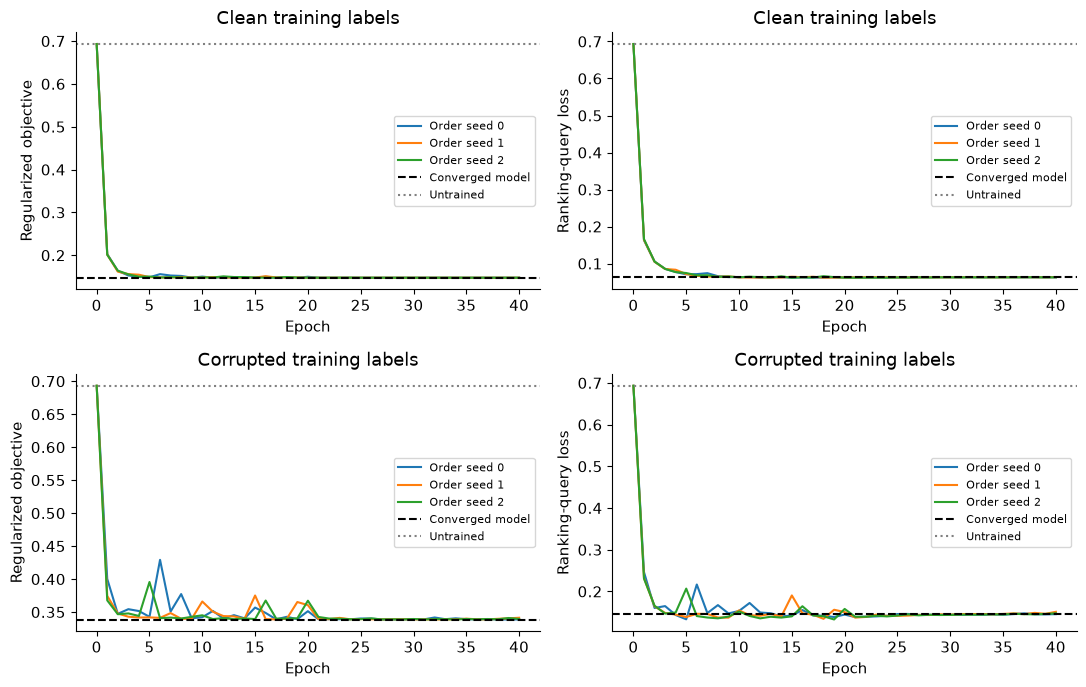

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, condition in enumerate(["clean", "corrupted"]):
    fits = fitted[condition]
    for seed, (trace, result) in enumerate(zip(fits["paths"], ranking_results[condition]["paths"])):
        states = trace["states"][::128]
        objective = weighted_objective(
            states,
            data["train"]["x"],
            fits["train_y"],
            torch.ones(len(states), 128, dtype=DTYPE),
            L2,
        )
        ranking_loss = query_outputs(states, data["ranking"])["losses"].mean(1)
        axes[row, 0].plot(range(41), objective, label=f"Order seed {seed}")
        axes[row, 1].plot(range(41), ranking_loss, label=f"Order seed {seed}")
    references = [
        float(fits["base"]["objective"][0]),
        float(ranking_results[condition]["baseline"]["losses"].mean()),
    ]
    for column in (0, 1):
        axes[row, column].axhline(
            references[column], color="black", ls="--", label="Converged model"
        )
        axes[row, column].axhline(math.log(2), color=".5", ls=":", label="Untrained")
        axes[row, column].set(
            xlabel="Epoch", ylabel="Regularized objective" if column == 0 else "Ranking-query loss"
        )
        axes[row, column].set_title(f"{condition.capitalize()} training labels")
        axes[row, column].legend(fontsize=8)
show_figure(fig, "attribution_native_training")


<details><summary>Interpretation — why also show loss when accuracy is perfect?</summary>

In the development run, both converged models classified all 48 ranking queries
correctly, but their mean losses were about 0.063 and 0.147. Accuracy hides that
confidence difference. The SGD paths also finish with nonzero objective gradients;
calling them converged would obscure the distinction between path attribution
and a derivative at the stationary reference model.

</details>

### Test the path approximation on the actual digit updates

The exact allocation must telescope to the observed loss reduction for each query.
The Taylor sum need not. The left panels compare their total reductions, averaged
over ranking queries. The right panels expose how their discrepancy accumulates.
The raw-only control leaves out a gradient term from the updates actually made.
A consistently small per-step error can still produce a large error after many
updates; keep the entire path, rather than showing a favorable short interval.


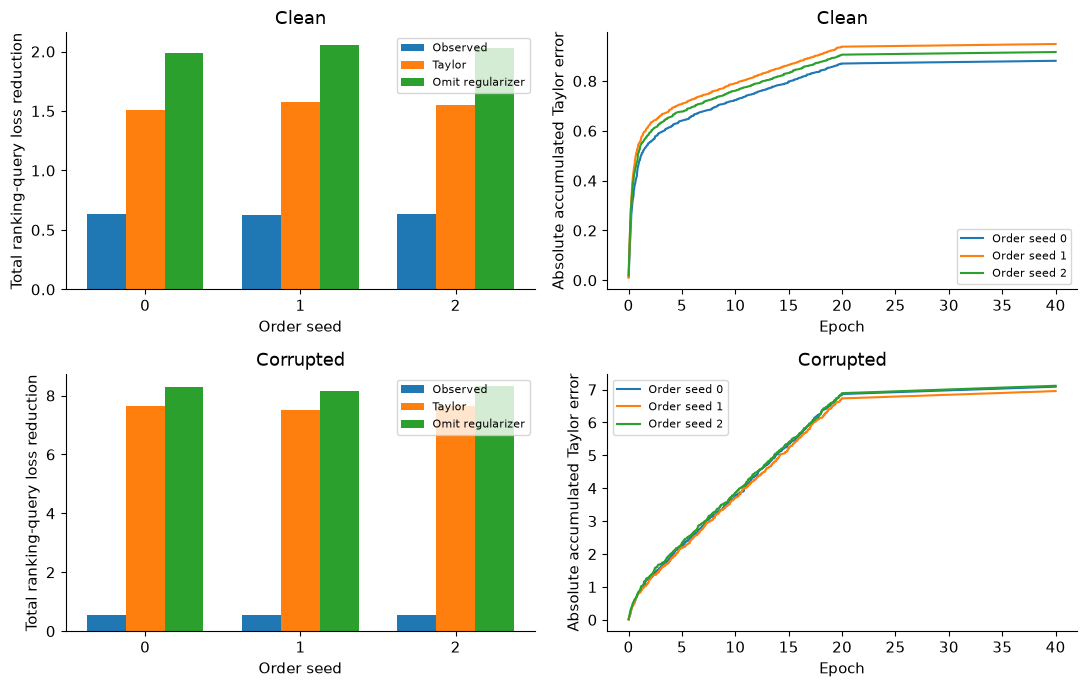

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, condition in enumerate(["clean", "corrupted"]):
    for offset, key, label in [
        (-0.25, "exact", "Observed"),
        (0, "first_order", "Taylor"),
        (0.25, "raw_only", "Omit regularizer"),
    ]:
        totals = [
            float(path["accounting"][key].sum(0).mean())
            for path in ranking_results[condition]["paths"]
        ]
        axes[row, 0].bar(np.arange(3) + offset, totals, width=0.25, label=label)
    for seed, path in enumerate(ranking_results[condition]["paths"]):
        exact = path["accounting"]["exact_steps"].mean(1).cumsum(0)
        taylor = path["accounting"]["first_order_steps"].mean(1).cumsum(0)
        axes[row, 1].plot(
            torch.arange(1, len(exact) + 1) / 128,
            (exact - taylor).abs(),
            label=f"Order seed {seed}",
        )
    axes[row, 0].axhline(0, color="black", lw=0.7)
    axes[row, 0].set(
        xlabel="Order seed", xticks=[0, 1, 2], ylabel="Total ranking-query loss reduction"
    )
    axes[row, 1].set(xlabel="Epoch", ylabel="Absolute accumulated Taylor error")
    for column in (0, 1):
        axes[row, column].set_title(condition.capitalize())
        axes[row, column].legend(fontsize=8)
show_figure(fig, "attribution_native_path_accounting")


## 🔟 Evaluate the frozen choices on final queries

All reference fits and removal policies above are now fixed. The following
function evaluates their already fitted parameters. It checks that both label
conditions have finished and does not select or retrain a model.

There are 64 final queries from the original test-writer group. Show all of them.
The influence/leave-one-out comparison answers the fixed-penalty removal question.
The checkpoint and exact-path comparisons relate a different attribution target
to that removal effect; disagreement is an outcome to understand.


In [28]:
def evaluate_final(fitted, train, final_queries, m, directory):
    """Evaluate already frozen fits and policies, after both conditions finish."""
    if set(fitted) != {"clean", "corrupted"}:
        raise ValueError("Both conditions must finish before final evaluation.")
    if any(value.get("stage") != "FITS_AND_RANKING_COMPLETE" for value in fitted.values()):
        raise ValueError(
            "Final evaluation cannot run before every fit and deletion policy is frozen."
        )
    final = {}
    for name, fits in fitted.items():
        final[name] = score_queries(fits, train, fits["train_y"], final_queries, m)
        final[name]["deletions"] = query_outputs(fits["deletions"]["theta"], final_queries)
        torch.save(final[name], directory / name / "final_measurements.pt")
    return final


In [29]:
final_results = evaluate_final(fitted, data["train"], data["final"], m, NATIVE_DIR)
query_data = data["final"]
results = final_results
print("All frozen conditions evaluated on the 64 final queries.")


All frozen conditions evaluated on the 64 final queries.


### Every training row, every final query

The signature result connects each attribution score to an actual retrained
model. Each point in the first column compares the influence-predicted removal loss
change with an actual independently refitted leave-one-out model. The diagonal
is exact agreement. Points with the wrong sign are red; tiny sign mistakes remain
in the plot and count, rather than being dropped using an outcome-dependent cutoff.

The other columns use checkpoint or retrieval scores. Their vertical axes are
scores, so an identity line would be misleading. Higher scores are interpreted
as more helpful examples. All three order seeds are shown for all-checkpoint
TracIn. The complete set of checkpoint choices follows in the next figure.


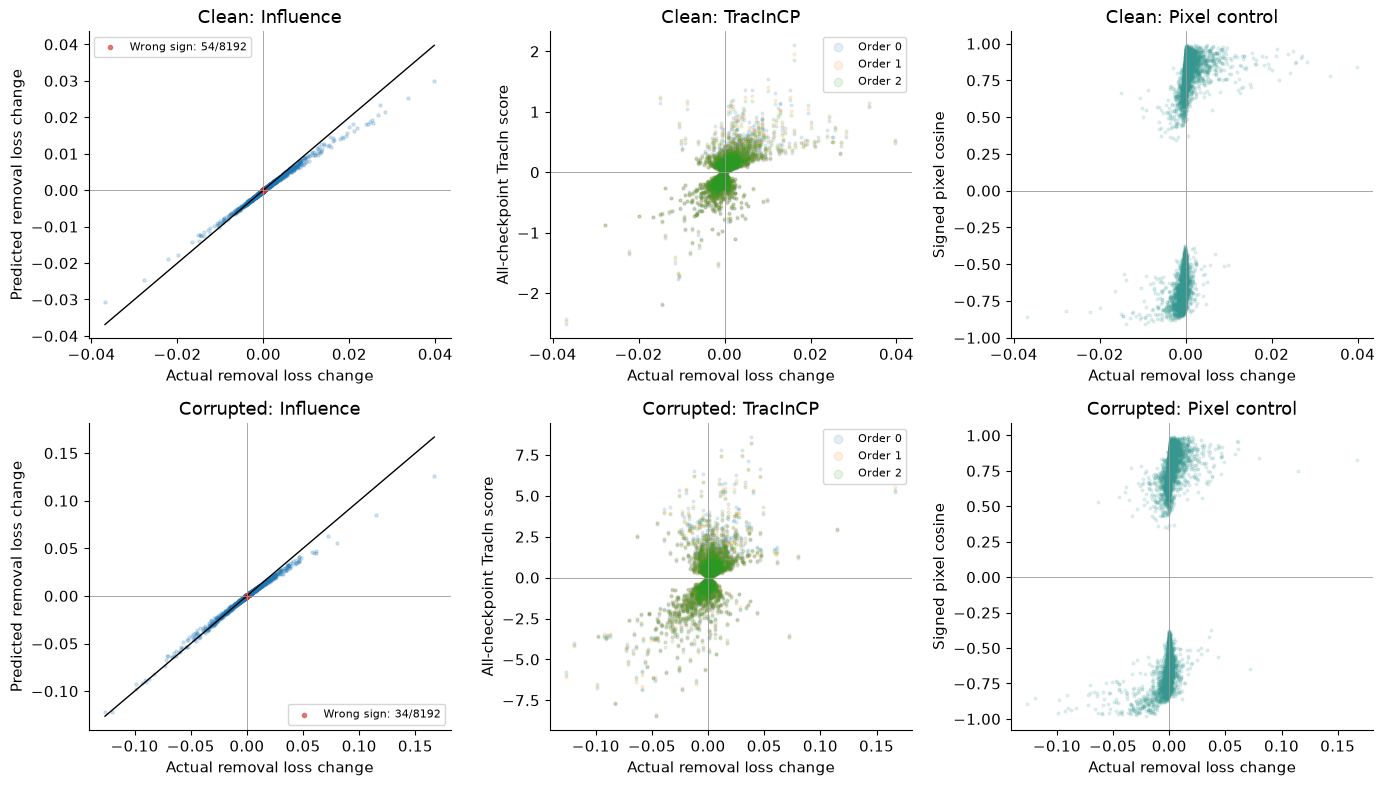

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, condition in enumerate(["clean", "corrupted"]):
    measured = results[condition]
    actual = measured["loo_loss_changes"]
    predicted = measured["removal_predictions"][0]
    wrong_sign = (actual > 0) != (predicted > 0)
    axes[row, 0].scatter(
        actual[~wrong_sign], predicted[~wrong_sign], s=5, alpha=0.18, rasterized=True
    )
    axes[row, 0].scatter(
        actual[wrong_sign],
        predicted[wrong_sign],
        s=9,
        color="#d73027",
        alpha=0.6,
        label=f"Wrong sign: {int(wrong_sign.sum())}/{actual.numel()}",
    )
    low, high = float(torch.minimum(actual.min(), predicted.min())), float(
        torch.maximum(actual.max(), predicted.max())
    )
    axes[row, 0].plot([low, high], [low, high], color="black", lw=1)
    axes[row, 0].set_ylabel("Predicted removal loss change")
    axes[row, 0].legend(fontsize=8)
    for seed, path in enumerate(measured["paths"]):
        axes[row, 1].scatter(
            actual,
            path["checkpoints"]["scores"]["all"],
            s=4,
            alpha=0.12,
            label=f"Order {seed}",
            rasterized=True,
        )
    axes[row, 1].set_ylabel("All-checkpoint TracIn score")
    axes[row, 1].legend(fontsize=8, markerscale=3)
    axes[row, 2].scatter(
        actual,
        measured["signed_pixel_similarity"],
        s=4,
        alpha=0.12,
        color="#35978f",
        rasterized=True,
    )
    axes[row, 2].set_ylabel("Signed pixel cosine")
    for column, label in enumerate(["Influence", "TracInCP", "Pixel control"]):
        axes[row, column].axhline(0, color=".6", lw=0.6)
        axes[row, column].axvline(0, color=".6", lw=0.6)
        axes[row, column].set_xlabel("Actual removal loss change")
        axes[row, column].set_title(f"{condition.capitalize()}: {label}")
show_figure(fig, "attribution_final_loo_comparison")


### Does agreement hold for each query?

A pooled correlation can hide a bad ranking for a particular image. Compute
Spearman correlation across training rows separately for every final query.
This asks whether the method orders examples like the actual removal experiment;
it does not ask whether its numeric scale is calibrated. Constant-score rankings
have undefined correlation and are displayed as missing, not silently as zero.

Keep all damping values, all three paths and all checkpoint choices. The exact
path rows are included to show that even exact accounting for a different
question need not reproduce leave-one-out rankings.


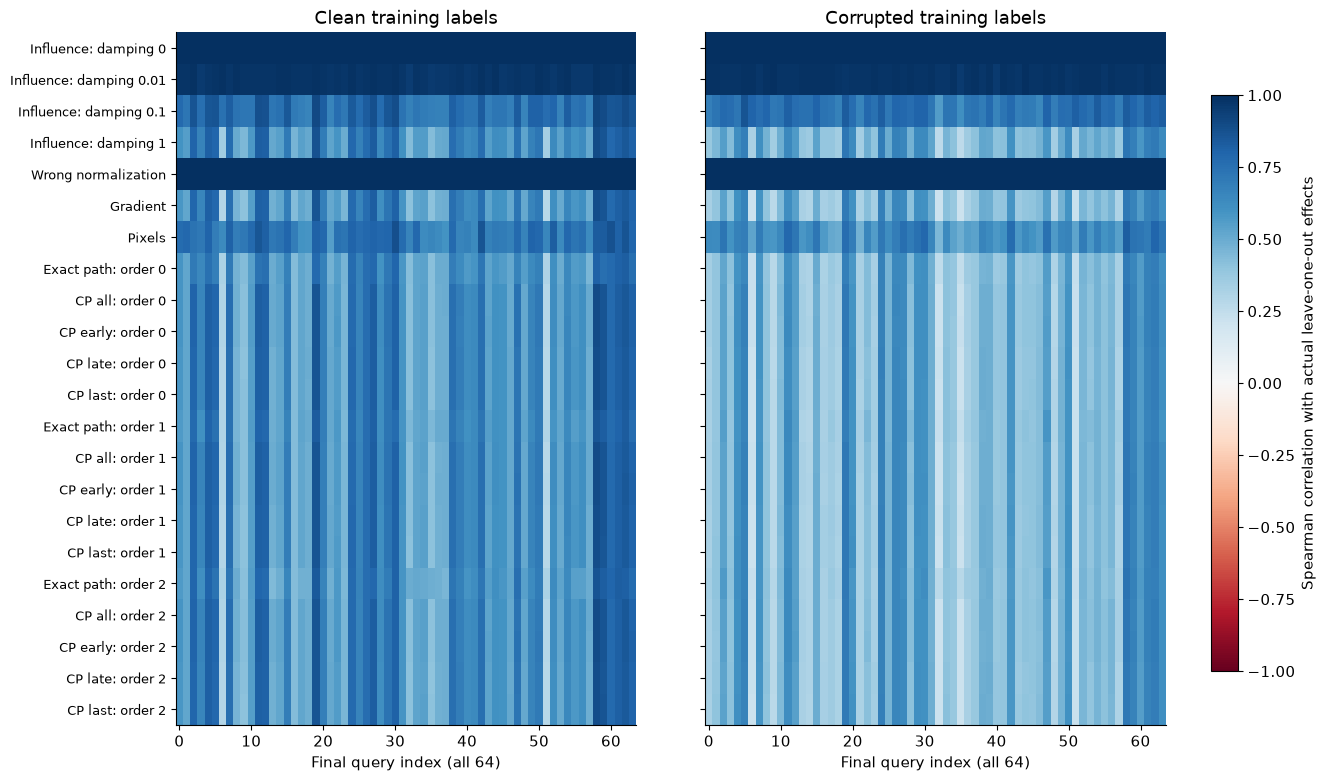

In [31]:
def per_query_spearman(actual, scores):
    a = rankdata(actual.numpy(), axis=0)
    b = rankdata(scores.numpy(), axis=0)
    a, b = a - a.mean(0), b - b.mean(0)
    denominator = np.sqrt((a * a).sum(0) * (b * b).sum(0))
    return np.divide(
        (a * b).sum(0), denominator, out=np.full_like(denominator, np.nan), where=denominator > 0
    )


fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharey=True)
for ax, condition in zip(axes, ["clean", "corrupted"]):
    measured = results[condition]
    methods_to_compare = [
        (f"Influence: damping {value:g}", measured["removal_predictions"][index])
        for index, value in enumerate(DAMPING)
    ]
    methods_to_compare += [
        ("Wrong normalization", measured["wrong_normalization"]),
        ("Gradient", measured["gradient_similarity"]),
        ("Pixels", measured["signed_pixel_similarity"]),
    ]
    for seed, path in enumerate(measured["paths"]):
        methods_to_compare.append((f"Exact path: order {seed}", path["accounting"]["exact"]))
        for name, scores in path["checkpoints"]["scores"].items():
            methods_to_compare.append((f"CP {name}: order {seed}", scores))
    correlations = np.stack(
        [
            per_query_spearman(measured["loo_loss_changes"], scores)
            for _, scores in methods_to_compare
        ]
    )
    im = ax.imshow(np.ma.masked_invalid(correlations), aspect="auto", vmin=-1, vmax=1, cmap="RdBu")
    ax.set(
        xlabel="Final query index (all 64)",
        title=f"{condition.capitalize()} training labels",
        yticks=range(len(methods_to_compare)),
    )
    ax.set_yticklabels([name for name, _ in methods_to_compare], fontsize=9)
fig.subplots_adjust(left=0.19, right=0.85, wspace=0.15)
colorbar_axis = fig.add_axes([0.88, 0.17, 0.018, 0.64])
fig.colorbar(im, cax=colorbar_axis, label="Spearman correlation with actual leave-one-out effects")
fig.savefig(OUTPUT / "attribution_final_query_agreement.png", dpi=150, bbox_inches="tight")
plt.show()


<details>
<summary>Interpreting the final scatter and heatmap</summary>

With the reference settings, undamped influence closely matches leave-one-out
rankings on every final query: per-query Spearman correlations exceed 0.997.
It still gives the wrong sign for 54 of 8192 clean-label pairs and 34 of 8192
corrupted-label pairs. Larger effects can visibly depart from the identity line,
so a near-perfect ranking is not an exact deletion prediction.

The wrong-normalization control has the same ranking as influence. Why?
Omitting $\nabla R$ subtracts the same training-gradient vector from every row.
For a fixed query, it shifts every score by the same constant. Spearman
correlation cannot detect that error; the derivative comparison below can.
This is a useful counterexample to validating an attribution method by ranking
agreement alone.

</details>

### Curvature is useful only at the right solution

The implicit derivative describes a stationary optimum. What happens if we
substitute the parameters after only one Newton update? Compare with an actual
central finite difference from two separately converged weighted fits, using
$\epsilon=\pm0.01/n$. Both sides use the same twelve prescribed training rows
and every final query. These are derivatives with respect to $\epsilon$, not
loss changes after deletion.

The left panels change how far optimization has progressed. The right panels
keep the converged solution but change the matrix used in the inverse. Damping
can stabilize an ill-conditioned solve; here the positive regularizer already
makes the Hessian invertible. Adding damping changes the answer and should not
be treated as a free improvement. The raw-loss-only control differentiates a
different regularization convention.


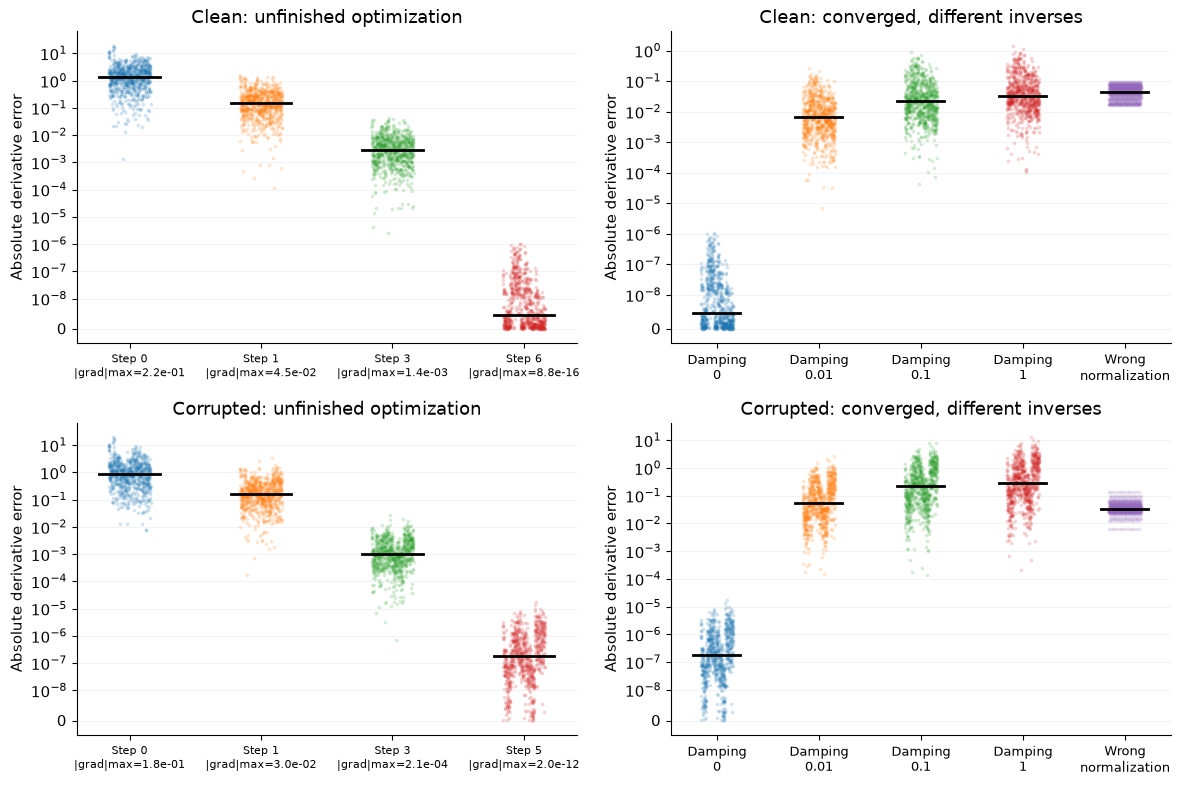

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, condition in enumerate(["clean", "corrupted"]):
    fits, measured = fitted[condition], results[condition]
    probes = fits["probe_indices"]
    finite = measured["finite_derivative"]
    unfinished = (measured["convergence_upweight"][:, probes] - finite[None]).abs().flatten(1)
    damped = (
        (-len(train["x"]) * measured["removal_predictions"][:, probes] - finite[None])
        .abs()
        .flatten(1)
    )
    wrong = (-len(train["x"]) * measured["wrong_normalization"][probes] - finite).abs().flatten()
    for ax, errors in zip(axes[row], [list(unfinished), [*damped, wrong]]):
        for column, error in enumerate(errors):
            offset = np.linspace(-0.16, 0.16, len(error))
            ax.scatter(column + offset, error, s=3, alpha=0.14)
            ax.plot(
                [column - 0.23, column + 0.23], [float(error.median())] * 2, color="black", lw=2
            )
        ax.set_yscale("symlog", linthresh=1e-8)
        ax.set_ylabel("Absolute derivative error")
        ax.grid(axis="y", alpha=0.15)
    indices = measured["convergence_state_indices"]
    axes[row, 0].set_xticks(
        range(4),
        [f"Step {i}\n|grad|max={float(fits['base']['gradient_norms'][i, 0]):.1e}" for i in indices],
        fontsize=8,
    )
    axes[row, 0].set_title(f"{condition.capitalize()}: unfinished optimization")
    axes[row, 1].set_xticks(
        range(5), [f"Damping\n{v:g}" for v in DAMPING] + ["Wrong\nnormalization"], fontsize=9
    )
    axes[row, 1].set_title(f"{condition.capitalize()}: converged, different inverses")
show_figure(fig, "attribution_final_derivative_controls")


<details>
<summary>Help — why is the final error not exactly zero?</summary>

The central difference is evaluated at finite, nonzero perturbations; its error
is second order in their size for a sufficiently smooth response. Each refit
also stops at a finite gradient tolerance. Compare the error scale with the
unfinished and mismatched-objective controls. Exact equality to a finite
difference is not the defining property of an infinitesimal derivative.

</details>

### From a local derivative to a finite removal

Now keep the whole perturbation curve. Each panel is one training image. The
horizontal axis is $s=n\epsilon$: $s=-1$ means completely remove that image,
while $s=1$ gives it twice the weight of another example. The regularizer stays
fixed in the normalized weighted objective. The vertical axis averages the
actual change in prediction loss across all 64 final queries.

Draw the linear prediction from the unperturbed solution; do not refit its slope
to the plotted points. The curves retain every chosen image, including flipped
and unflipped labels in both classes. The dashed control omits the training-row
regularizer in the derivative, while the refitted objective still includes it.


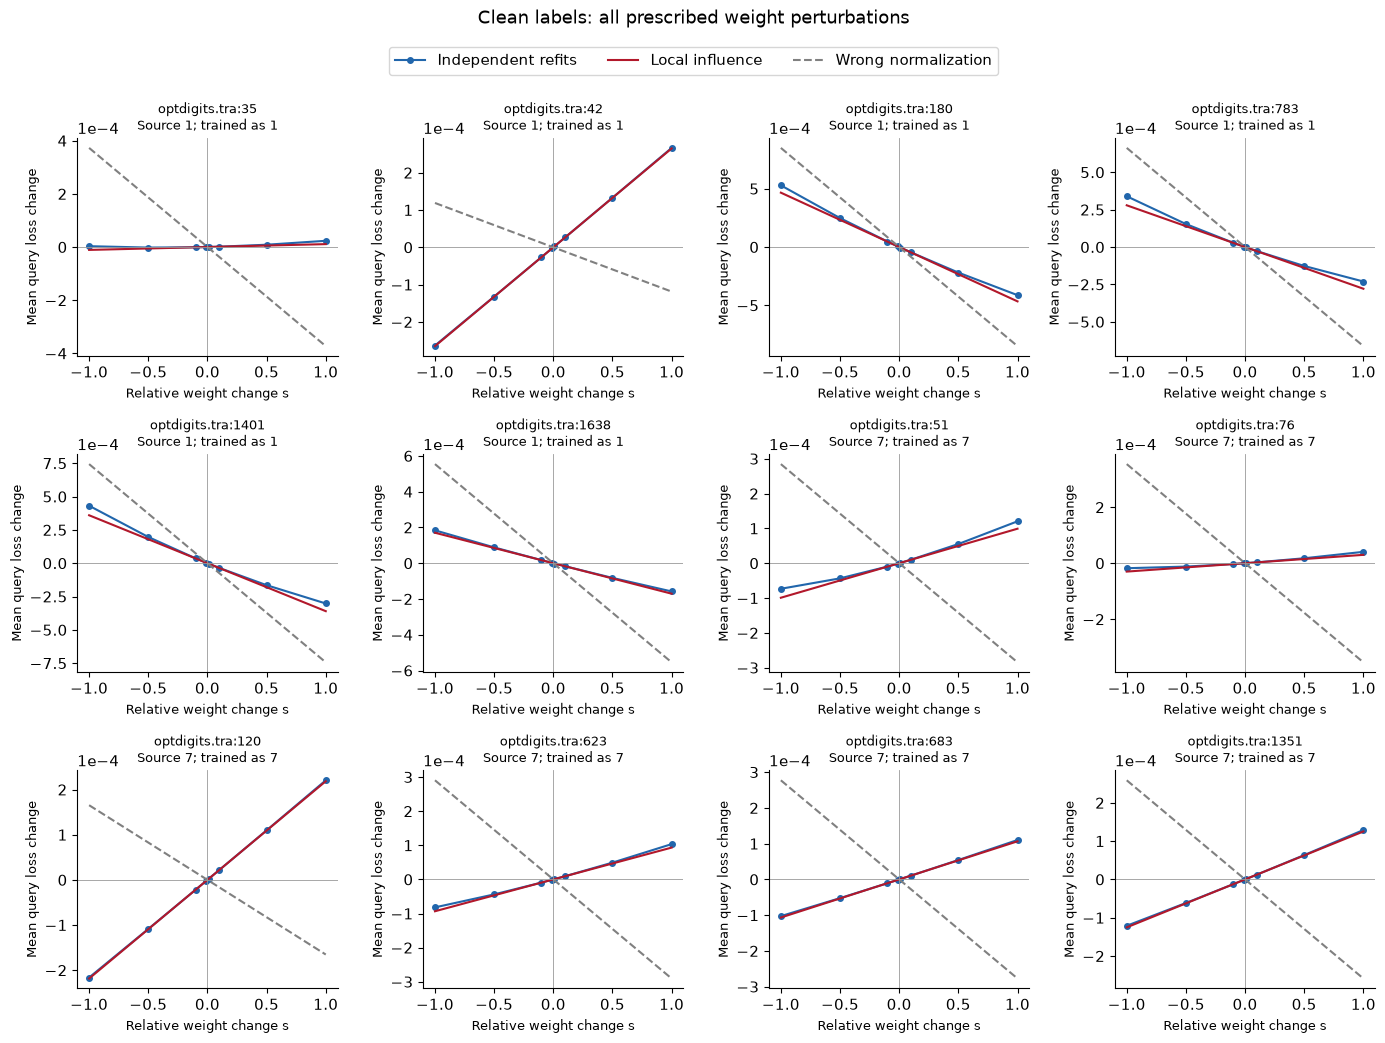

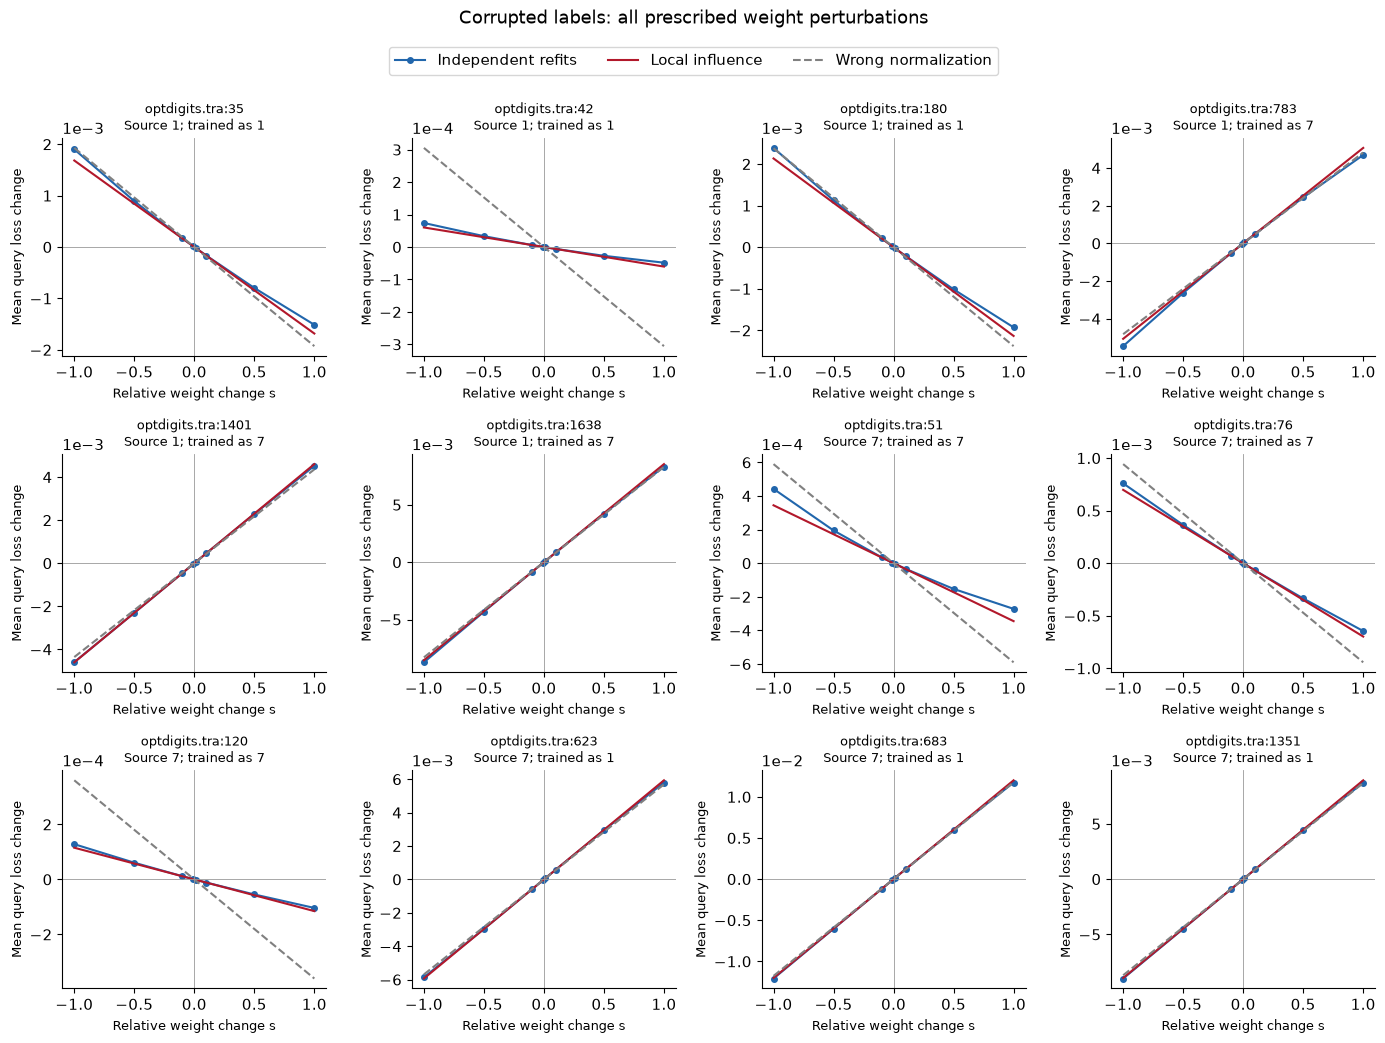

In [33]:
for condition in ["clean", "corrupted"]:
    fits, measured = fitted[condition], results[condition]
    actual = measured["perturbations"]["losses"].reshape(12, 8, -1).mean(2)
    actual -= measured["baseline"]["losses"].mean()
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    for panel, (ax, index) in enumerate(zip(axes.flat, fits["probe_indices"])):
        # -s * predicted deletion = epsilon * predicted upweight derivative.
        predicted = -np.array(STRENGTHS) * float(measured["removal_predictions"][0, index].mean())
        wrong = -np.array(STRENGTHS) * float(measured["wrong_normalization"][index].mean())
        ax.plot(STRENGTHS, actual[panel], "o-", color="#2166ac", label="Independent refits", ms=4)
        ax.plot(STRENGTHS, predicted, color="#b2182b", label="Local influence")
        ax.plot(STRENGTHS, wrong, "--", color=".5", label="Wrong normalization")
        ax.axhline(0, color=".6", lw=0.6)
        ax.axvline(0, color=".6", lw=0.6)
        true_digit = int(train["digit"][index])
        observed_digit = 7 if fits["train_y"][index] else 1
        ax.set_title(
            f"{train['ids'][index]}\nSource {true_digit}; trained as {observed_digit}", fontsize=9
        )
        ax.set_xlabel("Relative weight change s", fontsize=9)
        ax.set_ylabel("Mean query loss change", fontsize=9)
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.01))
    fig.suptitle(f"{condition.capitalize()} labels: all prescribed weight perturbations", y=1.04)
    show_figure(fig, f"attribution_final_perturbations_{condition}")


### Does removing the lowest-ranked data help new queries?

This is the intervention that a data-cleaning application might actually use.
Each ranking method selected examples using only the 48 ranking queries. We
then independently trained a new model for each deletion set. All methods remove
half their budget from each observed training class, so a change in class balance
cannot explain an advantage. The clean-label condition asks whether a method
only works when we deliberately introduce mistakes.

The grey lines retain all 32 matched random rankings; they are not confidence
intervals. The twelve purple curves retain all order/checkpoint choices, using
line style for checkpoint choice. “Ranking LOO” chooses by actual single-row
removal effects on ranking queries. It is an expensive comparison, not an oracle
for group deletion or for final-query outcomes.

The first column reports mean final loss relative to training on every example;
negative is better. The second reports final accuracy. Confidence can change
before an argmax changes, which is why both views matter.


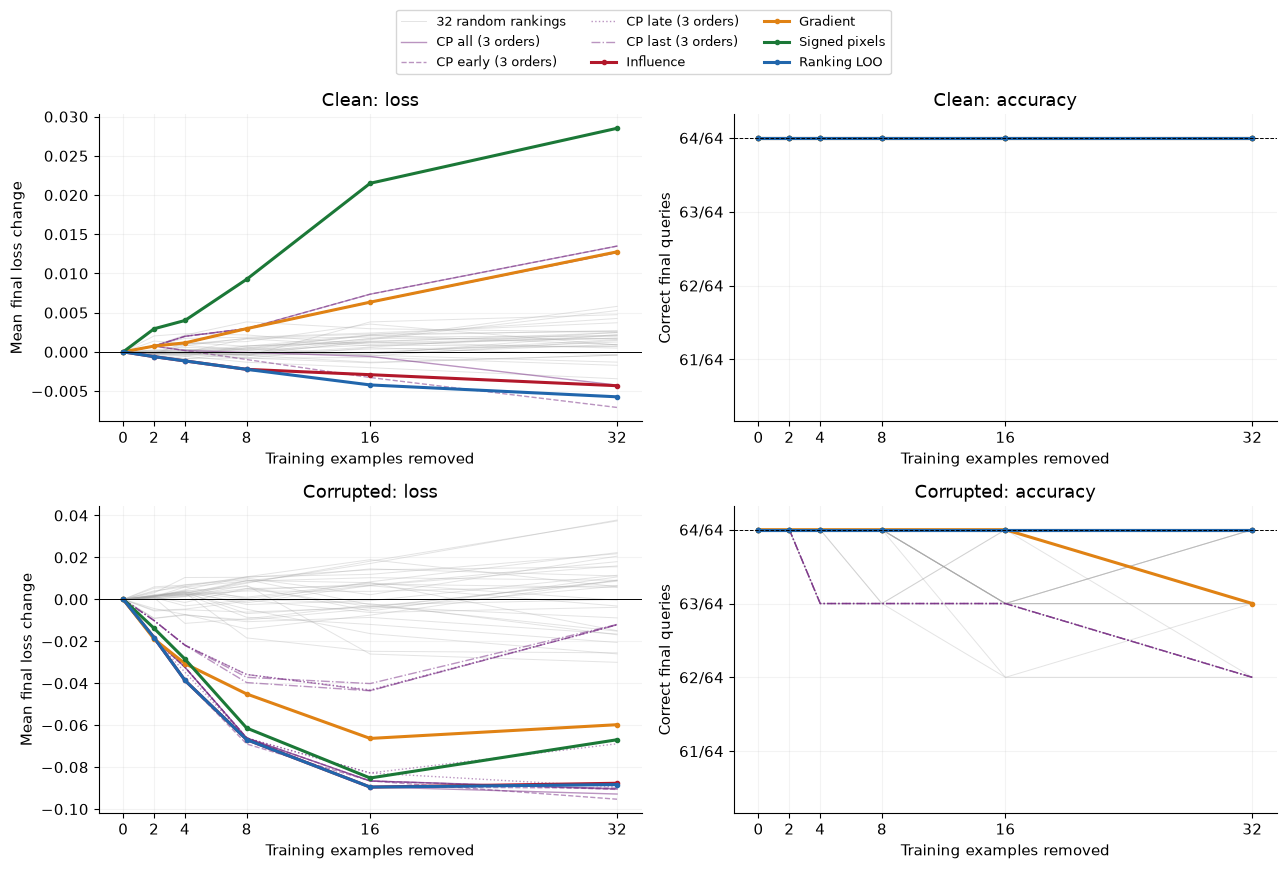

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
colors = {
    "influence": "#b2182b",
    "ranking_loo": "#2166ac",
    "gradient": "#e08214",
    "pixels": "#1b7837",
}
line_styles = {"all": "-", "early": "--", "late": ":", "last": "-."}
for row, condition in enumerate(["clean", "corrupted"]):
    fits, measured = fitted[condition], results[condition]
    baseline_loss = float(measured["baseline"]["losses"].mean())
    baseline_accuracy = float(measured["baseline"]["correct"].double().mean())
    names = list(fits["rankers"])
    # Draw random and checkpoint curves first so primary curves remain visible.
    names.sort(
        key=lambda name: 0 if name.startswith("random") else (1 if name.startswith("tracin") else 2)
    )
    for name in names:
        indices = [i for i, policy in enumerate(fits["policies"]) if policy["ranker"] == name]
        loss = [0.0, *(measured["deletions"]["losses"][indices].mean(1) - baseline_loss).tolist()]
        accuracy = [
            baseline_accuracy,
            *measured["deletions"]["correct"][indices].double().mean(1).tolist(),
        ]
        if name.startswith("random"):
            style = dict(
                color=".65",
                alpha=0.3,
                lw=0.7,
                label="32 random rankings" if name == "random_1000" else None,
            )
        elif name.startswith("tracin"):
            choice = name.rsplit("_", 1)[1]
            style = dict(
                color="#762a83",
                alpha=0.5,
                lw=1,
                ls=line_styles[choice],
                label=f"CP {choice} (3 orders)" if "seed0" in name else None,
            )
        else:
            style = dict(
                color=colors[name],
                lw=2.2,
                marker="o",
                ms=3,
                label={"ranking_loo": "Ranking LOO", "pixels": "Signed pixels"}.get(
                    name, name.capitalize()
                ),
            )
        for ax, values in zip(axes[row], [loss, accuracy]):
            ax.plot([0, *BUDGETS], values, **style)
    for ax in axes[row]:
        ax.set(xlabel="Training examples removed", xticks=[0, *BUDGETS])
        ax.grid(alpha=0.15)
    axes[row, 0].axhline(0, color="black", lw=0.7)
    axes[row, 1].axhline(baseline_accuracy, color="black", lw=0.7, ls="--")
    axes[row, 0].set(title=f"{condition.capitalize()}: loss", ylabel="Mean final loss change")
    axes[row, 1].set(
        title=f"{condition.capitalize()}: accuracy",
        ylabel="Correct final queries",
        ylim=(0.94, 1.005),
    )
    axes[row, 1].set_yticks(
        [i / 64 for i in (61, 62, 63, 64)], [f"{i}/64" for i in (61, 62, 63, 64)]
    )
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, 1.09))
show_figure(fig, "attribution_final_deletion_curves")


<details>
<summary>Interpreting the frozen deletion experiment</summary>

Both full-data models classify all 64 final images correctly. Their mean losses
are different: approximately 0.0822 with clean labels and 0.1732 with corrupted
labels. At budget 8, influence-selected removal changes these losses by -0.00223
and -0.0669 respectively. All 32 random changes lie above those two values at
that budget. This is evidence about these fixed subsets, not a population
confidence interval.

Checkpoint choice matters. On clean training labels, some checkpoint policies
increase final loss as the budget grows. With corrupted labels, some larger
checkpoint deletions reduce mean loss while also introducing classification
errors. Every clean-label deletion stays at 64/64; corrupted-label deletions
range from 62/64 to 64/64. Keep the loss and accuracy plots together.

</details>

### Look at the actual images behind a score

The four queries below were fixed by source-row order: the first two final
examples from each class. Each row shows the highest- and lowest-scoring training
image for influence, all-checkpoint TracIn with order seed 0, and signed pixel
similarity. The other two order seeds remain in the aggregate figures above.

Read each training tile in two ways: the method's score and the **actual** query
loss change after refitting without that image. Positive actual removal loss
means that the image helped this query. The same image may be helpful for one
query and harmful for another. A visually similar image, or an image with the
wrong training label, does not determine the answer by itself.


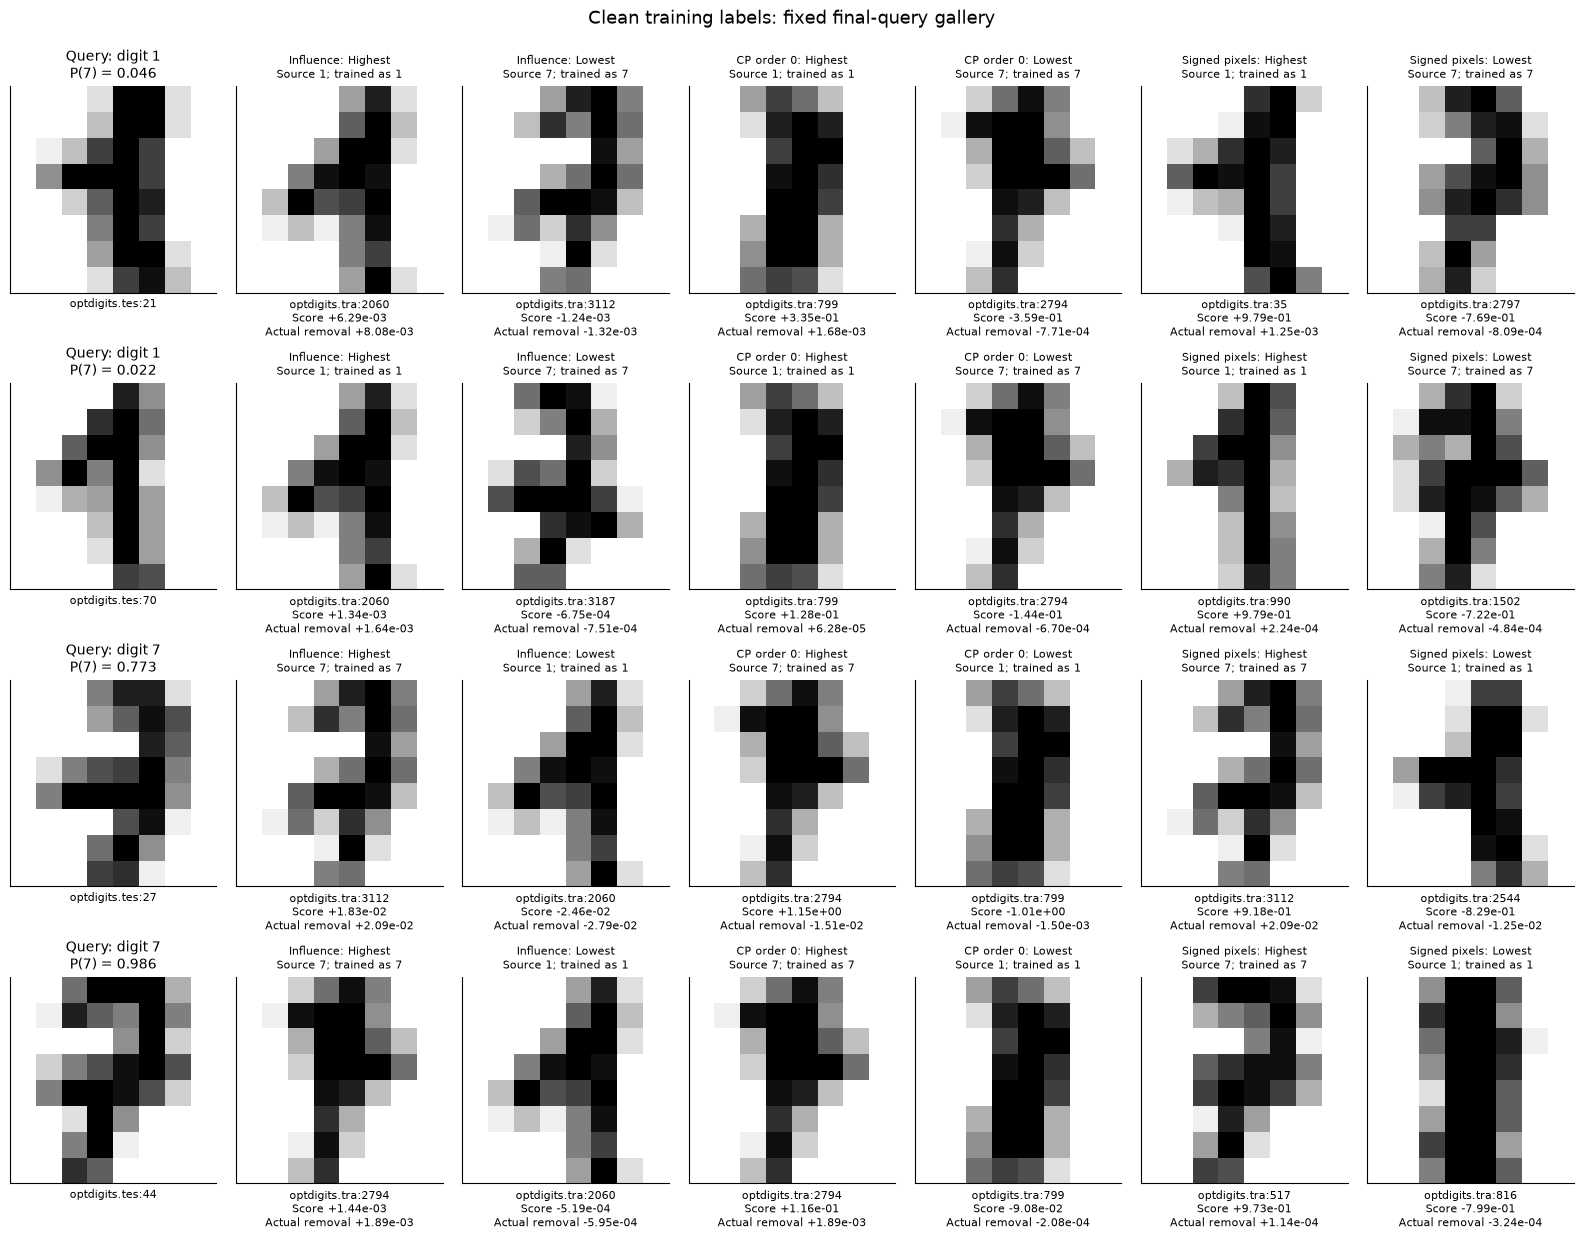

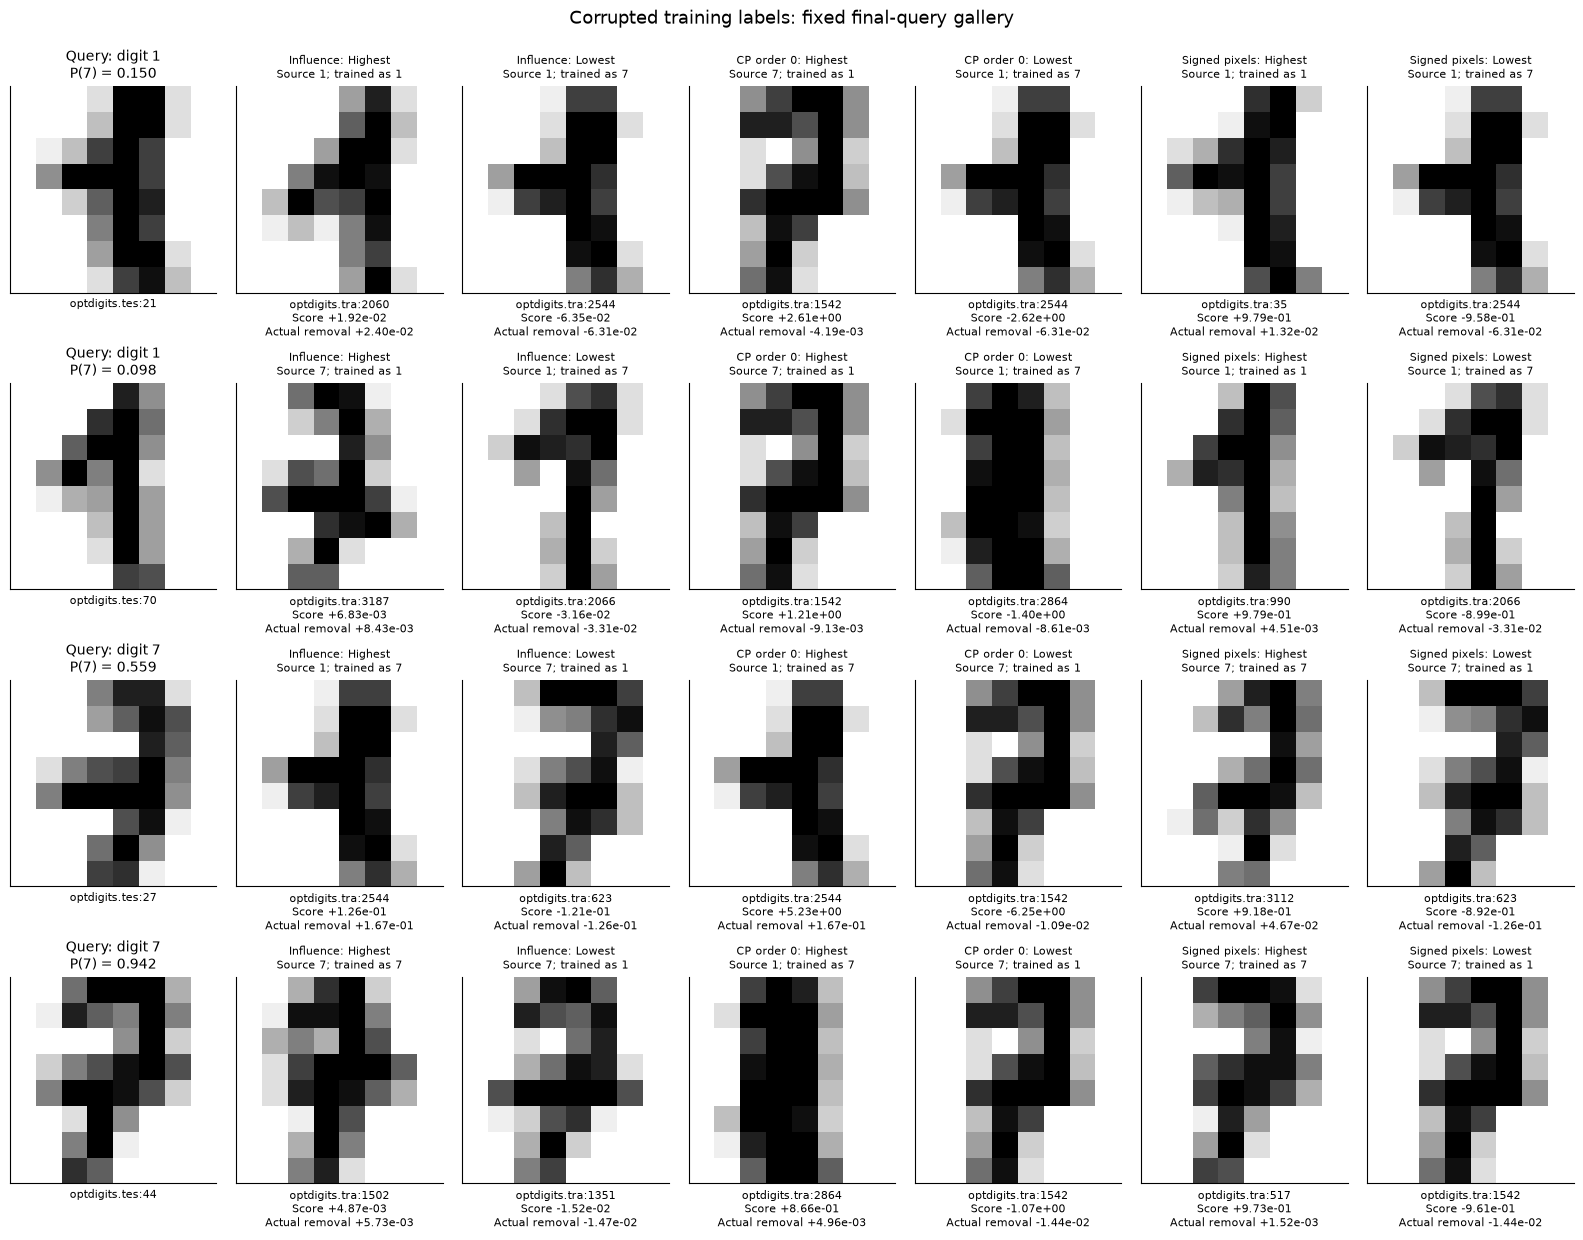

In [35]:
gallery_queries = [
    i
    for digit in (1, 7)
    for i in torch.nonzero(query_data["digit"] == digit).flatten().tolist()[:2]
]
for condition in ["clean", "corrupted"]:
    fits, measured = fitted[condition], results[condition]
    methods_for_gallery = [
        ("Influence", measured["removal_predictions"][0]),
        ("CP order 0", measured["paths"][0]["checkpoints"]["scores"]["all"]),
        ("Signed pixels", measured["signed_pixel_similarity"]),
    ]
    fig, axes = plt.subplots(4, 7, figsize=(16, 12))
    for row, query_index in enumerate(gallery_queries):
        axes[row, 0].imshow(query_data["images"][query_index], cmap="gray_r", vmin=0, vmax=1)
        probability = float(measured["baseline"]["probabilities"][0, query_index])
        axes[row, 0].set_title(
            f"Query: digit {int(query_data['digit'][query_index])}\nP(7) = {probability:.3f}",
            fontsize=10,
        )
        axes[row, 0].set_xlabel(query_data["ids"][query_index], fontsize=8)
        for method_index, (name, scores) in enumerate(methods_for_gallery):
            for side, (label, choose) in enumerate(
                [("Highest", torch.argmax), ("Lowest", torch.argmin)]
            ):
                index = int(choose(scores[:, query_index]))
                ax = axes[row, 1 + 2 * method_index + side]
                ax.imshow(train["images"][index], cmap="gray_r", vmin=0, vmax=1)
                true_digit, observed = int(train["digit"][index]), (
                    7 if fits["train_y"][index] else 1
                )
                actual = float(measured["loo_loss_changes"][index, query_index])
                ax.set_title(
                    f"{name}: {label}\nSource {true_digit}; trained as {observed}", fontsize=8
                )
                ax.set_xlabel(
                    f"{train['ids'][index]}\nScore {float(scores[index, query_index]):+.2e}\nActual removal {actual:+.2e}",
                    fontsize=8,
                )
    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"{condition.capitalize()} training labels: fixed final-query gallery", y=1.01)
    show_figure(fig, f"attribution_final_gallery_{condition}", h_pad=4)


<details>
<summary>Interpreting a disagreement in the fixed gallery</summary>

For clean training labels and query `optdigits.tes:27`, the highest TracInCP
example is `optdigits.tra:2794`. Its actual removal **reduces** the query loss
by about 0.0151. Influence instead selects `optdigits.tra:3112`, whose removal
increases loss by about 0.0209. The checkpoint score and the removal experiment
do not agree on which image helped.

In the corrupted-label gallery, training row `optdigits.tra:2544` is a source
digit 1 trained as 7. It hurts the first digit-1 query but helps the displayed
digit-7 query. This is possible because helpfulness is relative to the query
loss; a corrupted label does not give every query the same response.

</details>

## 1️⃣1️⃣ Check the ghost product inside the real classifier

The earlier affine-layer identity should hold at actual learned parameters,
including the bias. At every checkpoint we compared its product for every
training/query pair with complete parameter gradients. The training regularizer
contributes an additional term; it must not disappear when we factor the raw
loss gradient. No parameter-gradient approximation is needed for this single
linear layer.

The panels below compare the resulting all-checkpoint scores. The diagonal is
exact agreement. As a control, roll the training residuals by one row while
leaving the input images fixed. This changes which image receives which
backpropagated derivative. The scores should fail to match even though the
residual distribution is preserved.


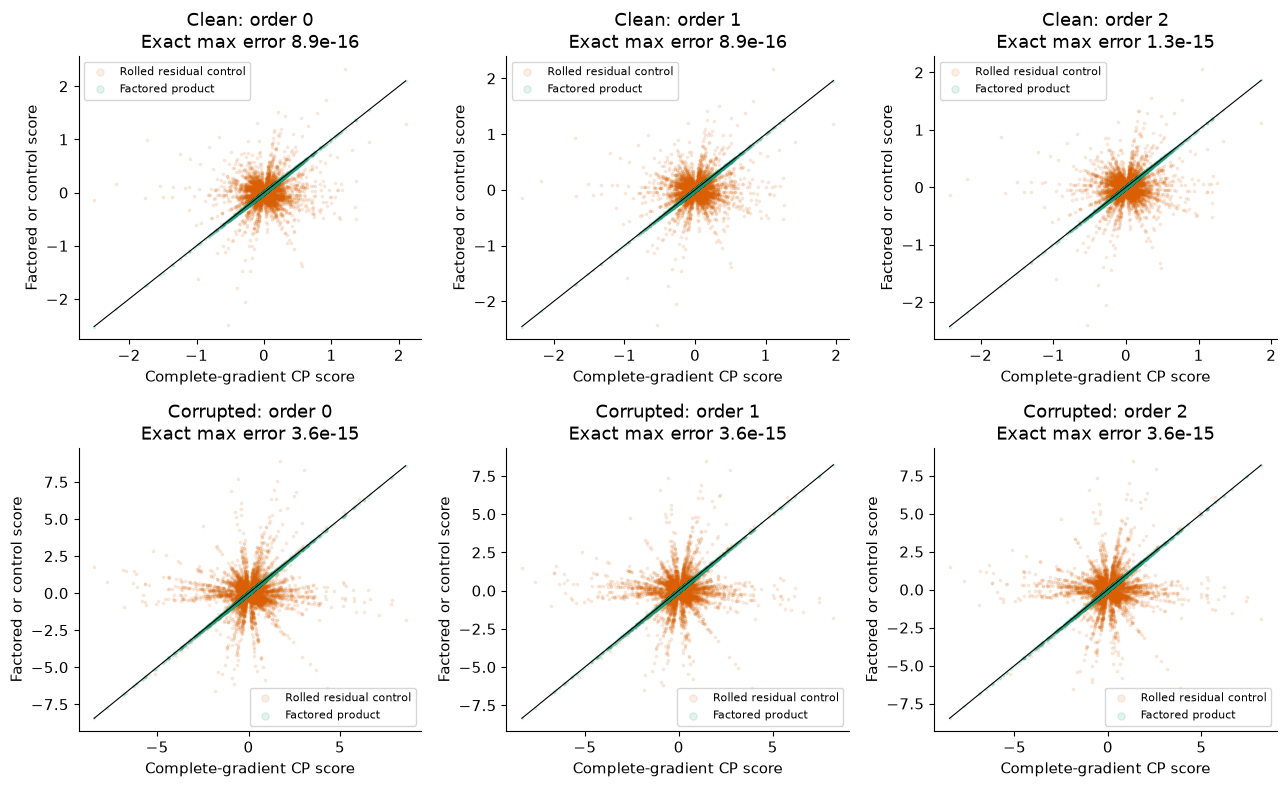

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
ghost_control_errors = {}
for row, condition in enumerate(["clean", "corrupted"]):
    ghost_control_errors[condition] = []
    for seed, path in enumerate(results[condition]["paths"]):
        cp = path["checkpoints"]
        dense, factored = cp["scores"]["all"], cp["ghost_all_scores"]
        shuffled = torch.zeros_like(dense)
        for theta, rate in zip(cp["checkpoints"], cp["checkpoint_rates"]):
            train_delta = torch.sigmoid(train["x"] @ theta) - fitted[condition]["train_y"]
            query_delta = torch.sigmoid(query_data["x"] @ theta) - query_data["y"]
            raw = ghost_linear_products(
                train["x"][:, :-1],
                train_delta.roll(1)[:, None],
                query_data["x"][:, :-1],
                query_delta[:, None],
            )
            query_gradient = logistic_gradients(theta, query_data["x"], query_data["y"])
            shuffled += rate * (raw + (L2 * theta @ query_gradient.T)[None, :])
        ax = axes[row, seed]
        ax.scatter(
            dense,
            shuffled,
            s=3,
            alpha=0.1,
            color="#d95f02",
            label="Rolled residual control",
            rasterized=True,
        )
        ax.scatter(
            dense,
            factored,
            s=3,
            alpha=0.12,
            color="#1b9e77",
            label="Factored product",
            rasterized=True,
        )
        ax.plot(
            [float(dense.min()), float(dense.max())],
            [float(dense.min()), float(dense.max())],
            color="black",
            lw=0.8,
        )
        error = float((factored - dense).abs().max())
        control_error = float((shuffled - dense).abs().mean())
        ghost_control_errors[condition].append(control_error)
        ax.set(
            title=f"{condition.capitalize()}: order {seed}\nExact max error {error:.1e}",
            xlabel="Complete-gradient CP score",
            ylabel="Factored or control score",
        )
        ax.legend(fontsize=8, markerscale=3)
show_figure(fig, "attribution_native_ghost_products")


This validates one affine invocation on this classifier. It is not a benchmark
of the GhostSuite package, nor a derivation for tied parameters, repeated token
positions or a whole transformer. Summing products across independent parameter
blocks requires care; multiplying tokenwise summaries can drop cross terms when
a parameter is reused. Here the 65-parameter model lets us keep the complete
gradients as an independent comparison.

## 1️⃣2️⃣ Try It Yourself — clean data for one query

Change the query index, training-label condition or even deletion budget below.
The cell recomputes influence for that query, selects the lowest-scoring examples
with matched observed-class counts, and **restarts training** after removing them.
It also retrains all 32 class-matched random deletions at the same budget.

This is an exploratory intervention for the selected ranking query. Because its
label chooses the removal set, its improvement is not held-out generalization.
The reference curves above remain based on frozen policies evaluated on separate
final queries. Try comparing the chosen set between a digit 1 and a digit 7.
Does the lowest-ranked image stay the same?


In [37]:
PLAY_CONDITION = "corrupted"  # "clean" or "corrupted"
PLAY_QUERY = 0  # 0 ... 47 in the ranking split
PLAY_BUDGET = 4  # an even number between 2 and 32


In [38]:
def query_deletion_play(train, query, fits, m, budget=4, l2=0.02):
    """Choose by this query, then refit the chosen set and 32 matched controls.

    This is an exploratory query-specific intervention, not a held-out policy
    evaluation. It does not change any reference-study fits or deletion policies.
    """
    n = len(train["x"])
    theta, labels = fits["base"]["theta"][0], fits["train_y"]
    _, hessian = m.objective_derivatives(
        theta[None],
        train["x"],
        labels,
        torch.ones(1, n, dtype=theta.dtype),
        l2,
    )
    scores = (
        -m.upweight_influence(
            hessian[0],
            m.logistic_gradients(theta, train["x"], labels, l2),
            m.logistic_gradients(theta, query["x"], query["y"]),
        )[:, 0]
        / n
    )
    selected = [m.class_matched_removals(scores, labels, budget)]
    for seed in range(1000, 1032):
        random_scores = torch.rand(
            n, generator=torch.Generator().manual_seed(seed), dtype=theta.dtype
        )
        selected.append(m.class_matched_removals(random_scores, labels, budget))
    weights = torch.ones(33, n, dtype=theta.dtype)
    for row, removed in enumerate(selected):
        weights[row, removed] = 0
    refits = m.fit_weighted_logistic(train["x"], labels, weights, l2)
    all_theta = torch.cat([theta[None], refits["theta"]])
    logits = all_theta @ query["x"].T
    losses = torch.nn.functional.softplus(logits) - query["y"][None, :] * logits
    return {
        "budget": budget,
        "query_ids": query["ids"],
        "scores": scores,
        "selected": selected,
        "weights": weights,
        "refits": refits,
        "probabilities": torch.sigmoid(logits),
        "losses": losses,
        "loss_changes": losses[1:] - losses[:1],
    }


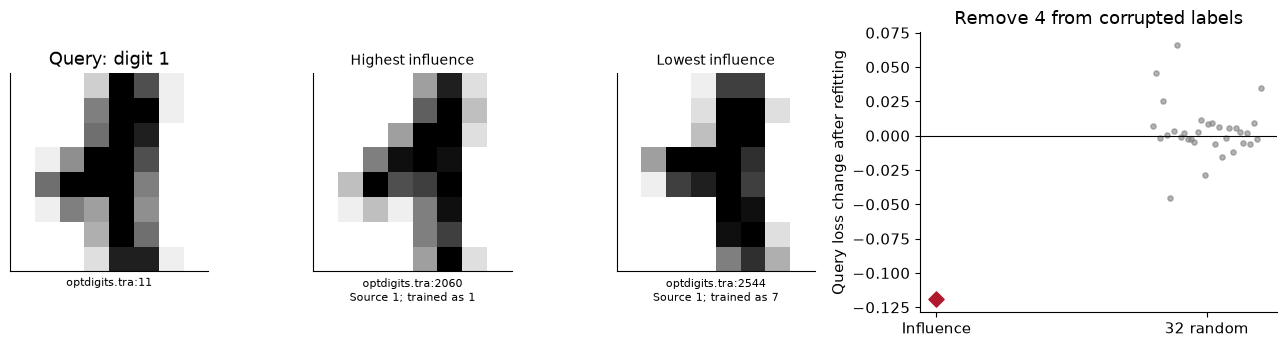

Query P(7): 0.215 before; 0.116 after selected removal.


In [39]:
assert PLAY_CONDITION in fitted and 0 <= PLAY_QUERY < 48
assert PLAY_BUDGET in range(2, 33, 2)
play_query = {
    "x": data["ranking"]["x"][PLAY_QUERY : PLAY_QUERY + 1],
    "y": data["ranking"]["y"][PLAY_QUERY : PLAY_QUERY + 1],
    "ids": [data["ranking"]["ids"][PLAY_QUERY]],
}
play_result = query_deletion_play(train, play_query, fitted[PLAY_CONDITION], m, budget=PLAY_BUDGET)
torch.save(play_result, NATIVE_DIR / "query_play.pt")
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.8]})
axes[0].imshow(data["ranking"]["images"][PLAY_QUERY], cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title(f"Query: digit {int(data['ranking']['digit'][PLAY_QUERY])}")
axes[0].set_xlabel(play_query["ids"][0], fontsize=8)
for ax, (label, choose) in zip(
    axes[1:3], [("Highest influence", torch.argmax), ("Lowest influence", torch.argmin)]
):
    index = int(choose(play_result["scores"]))
    ax.imshow(train["images"][index], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel(
        f"{train['ids'][index]}\nSource {int(train['digit'][index])}; trained as {7 if fitted[PLAY_CONDITION]['train_y'][index] else 1}",
        fontsize=8,
    )
for ax in axes[:3]:
    ax.set_xticks([])
    ax.set_yticks([])
changes = play_result["loss_changes"][:, 0]
axes[3].scatter(
    np.linspace(0.8, 1.2, 32), changes[1:], color=".5", s=14, alpha=0.6, label="Each random refit"
)
axes[3].scatter([0], changes[:1], color="#b2182b", s=60, marker="D", label="Influence selection")
axes[3].axhline(0, color="black", lw=0.8)
axes[3].set(
    xticks=[0, 1],
    xticklabels=["Influence", "32 random"],
    ylabel="Query loss change after refitting",
    title=f"Remove {PLAY_BUDGET} from {PLAY_CONDITION} labels",
)
show_figure(fig, "attribution_native_query_play")
print(
    f"Query P(7): {float(play_result['probabilities'][0, 0]):.3f} before; {float(play_result['probabilities'][1, 0]):.3f} after selected removal."
)


<details>
<summary>Help — an investigation to try next</summary>

Choose two queries with different true labels. Write down a prediction before
running each intervention. Record the source IDs removed, not just the two
extreme images shown. Increasing the budget changes a group intervention, so
adding individual influence predictions need not capture interactions or the
movement of the optimum. Compare the refitted loss change with the full spread
of random controls, and check whether an apparent benefit also occurs with clean
training labels. If you explore final queries after seeing the results, describe
that exploration separately from the fixed reference experiment.

</details>

## What have we learned?

A data-attribution score is a claim about a particular experiment. An influence
function is local to a stationary optimum and a weighting convention. Exact
path accounting adds up the loss changes on one recorded training trajectory;
its sum telescopes, but its division among examples depends on training order.
TracInCP samples gradient alignments at checkpoints and has neither the exact
path's telescoping identity nor influence's inverse-curvature correction.

These differences are testable. Use the refit scatter to ask about calibration
and sign, the per-query heatmap to ask about ranking, and the deletion curves to
ask about a group intervention. None can substitute for the other two.

## Limitations

All results here concern a regularized binary logistic classifier, one small
writer-separated digit subset and the stated label corruption. They establish
neither attribution accuracy for a large nonconvex network nor a universal
procedure for cleaning a training corpus.

Further investigations:

- Derive the influence formula if the bias is unregularized. Which convexity
  guarantee and objective derivatives would need to change?
- Use the same recorded states to study the contribution of the regularizer
  to the Taylor error. Explain why smaller step sizes and more checkpoints
  answer different approximation questions.
- Find a training image whose measured removal effect changes sign across
  queries. Explain the result using the image, the labels and the model's
  probabilities before looking at its attribution score.
- Predict what would break if we trained with momentum or a minibatch containing
  several examples. The current path formula validates single-example SGD;
  derive the changed update before implementing the extension.

Read the original methods alongside your derivations:

- [Koh and Liang (2017), Understanding Black-box Predictions via Influence Functions](https://proceedings.mlr.press/v70/koh17a.html).
  Compare the implicit derivative, inverse-Hessian computation and assumptions
  with the convex model used here.
- [Pruthi et al. (2020), Estimating Training Data Influence by Tracing Gradient Descent](https://proceedings.neurips.cc/paper/2020/hash/e6385d39ec9394f2f3a354d9d2b88eec-Abstract.html).
  Compare exact path effects, first-order approximations, checkpoint heuristics
  and the meaning of a proponent or opponent.


In [40]:
# Save supporting run metadata; the figures and actual interventions above
# are the learning results. Tensor artifacts retain every prescribed case.
native_summary = {
    "scope": "real_digit_influence_and_tracin",
    "native_model_executed": True,
    "native_directory": str(NATIVE_DIR),
    "device": "cpu",
    "dtype": "float64",
    "train_count": 128,
    "ranking_query_count": 48,
    "final_query_count": 64,
    "reference_refits": sum(
        sum(len(value[key]["theta"]) for key in ("base", "loo", "perturbations", "deletions"))
        for value in fitted.values()
    ),
    "sgd_paths": sum(len(value["paths"]) for value in fitted.values()),
    "sgd_updates": sum(
        len(path["used_ids"]) for value in fitted.values() for path in value["paths"]
    ),
    "policy_selection_queries": "ranking_only",
    "final_evaluated_after_both_reference_conditions_complete": True,
    "independent_scipy_checks": native_reference_checks,
    "separate_refit_checks": 6,
    "exploratory_play": {
        "condition": PLAY_CONDITION,
        "query_index": PLAY_QUERY,
        "budget": PLAY_BUDGET,
        "refits": len(play_result["refits"]["theta"]),
        "selected_loss_change": float(play_result["loss_changes"][0, 0]),
    },
    "conditions": {},
}
for condition in ["clean", "corrupted"]:
    fits, measured = fitted[condition], results[condition]
    actual, prediction = measured["loo_loss_changes"], measured["removal_predictions"][0]
    native_summary["conditions"][condition] = {
        "final_correct": int(measured["baseline"]["correct"].sum()),
        "final_loss": float(measured["baseline"]["losses"].mean()),
        "influence_wrong_sign": int(((actual > 0) != (prediction > 0)).sum()),
        "train_query_pairs": actual.numel(),
        "per_query_influence_spearman": per_query_spearman(actual, prediction).tolist(),
        "max_refit_gradient": max(
            float(fits[key]["gradient_norms"][-1].max())
            for key in ("base", "loo", "perturbations", "deletions")
        ),
        "max_ghost_error": max(
            path["checkpoints"]["ghost_max_error"] for path in measured["paths"]
        ),
        "rolled_residual_control_mean_errors": ghost_control_errors[condition],
        "rankers": len(fits["rankers"]),
        "deletion_policies": len(fits["policies"]),
        "gallery_query_ids": [query_data["ids"][i] for i in gallery_queries],
    }
(OUTPUT / "native_summary.json").write_text(
    json.dumps(native_summary, indent=2, allow_nan=False) + "\n"
)
print("Saved the full study and editable-query results.")


Saved the full study and editable-query results.
